In [ ]:
# IMD1151 - Ciência de Dados (2026.2)
## Checkpoint 1 (CP1) - Coleta Automatizada e Unificação dos 12 Arquivos Históricos
**Tema:** Análise Histórica e Comparativa da Criminalidade no Brasil (Sinesp-VDE)
**Fonte dos Dados:** Ministério da Justiça e Segurança Pública (MJSP) – Sinesp-VDE
**URL Oficial:** https://www.gov.br/mj/pt-br/assuntos/sua-seguranca/seguranca-publica/estatistica/dados-nacionais-1/base-de-dados-e-notas-metodologicas-dos-gestores-estaduais-sinesp-vde-2022-e-2023

Este notebook implementa a automação para descarregamento, normalização de cabeçalhos, consolidação e avaliação de consistência dos **12 ficheiros anuais/históricos** do validador estatístico nacional.

SyntaxError: invalid character '–' (U+2013) (511218029.py, line 4)

In [ ]:
#==========================================
#==========================================
#COLETA DE DADOS
#==========================================
#==========================================

In [ ]:
import os
import re
import zipfile
import shutil
import unicodedata
from pathlib import Path

import pandas as pd
from IPython.display import display
from google.colab import files

print("Envie o arquivo BancoVDE.zip")
uploaded = files.upload()

if not uploaded:
    raise ValueError("Nenhum arquivo foi enviado.")

nome_zip = next(iter(uploaded))

if not nome_zip.lower().endswith(".zip"):
    raise ValueError("Envie um arquivo .zip.")

PASTA_DADOS = Path("/content/dados_sinesp")
PASTA_TEMP = Path("/content/csv_temporarios")
PASTA_SAIDA = Path("/content/resultados_cp1")

for pasta in [PASTA_DADOS, PASTA_TEMP, PASTA_SAIDA]:
    if pasta.exists():
        shutil.rmtree(pasta)
    pasta.mkdir(parents=True, exist_ok=True)

# Extrai o ZIP com uma verificação básica de segurança
with zipfile.ZipFile(nome_zip, "r") as arquivo_zip:
    for membro in arquivo_zip.infolist():
        destino = (PASTA_DADOS / membro.filename).resolve()

        if not destino.is_relative_to(PASTA_DADOS.resolve()):
            raise ValueError("O ZIP contém um caminho de extração inválido.")

    arquivo_zip.extractall(PASTA_DADOS)

print("Arquivos extraídos com sucesso.")

Envie o arquivo BancoVDE.zip


Saving BancoVDE.zip to BancoVDE.zip
Arquivos extraídos com sucesso.


In [ ]:
def normalizar_colunas(colunas):
    resultado = []

    for coluna in colunas:
        nome = str(coluna).strip().lower()

        nome = unicodedata.normalize("NFKD", nome)
        nome = nome.encode("ascii", errors="ignore").decode("utf-8")
        nome = re.sub(r"\s+", "_", nome)
        nome = re.sub(r"[^\w]", "", nome)

        resultado.append(nome)

    if len(resultado) != len(set(resultado)):
        raise ValueError(
            "Existem nomes de colunas duplicados após a padronização."
        )

    return resultado


extensoes = {".xlsx", ".xls", ".csv"}

arquivos_dados = sorted(
    arquivo
    for arquivo in PASTA_DADOS.rglob("*")
    if arquivo.is_file() and arquivo.suffix.lower() in extensoes
)

if not arquivos_dados:
    raise FileNotFoundError(
        "Nenhum arquivo XLSX, XLS ou CSV foi encontrado no ZIP."
    )

print(f"Total de arquivos encontrados: {len(arquivos_dados)}")

for arquivo in arquivos_dados:
    print("-", arquivo.name)

Total de arquivos encontrados: 12
- BancoVDE 2015.xlsx
- BancoVDE 2016.xlsx
- BancoVDE 2017.xlsx
- BancoVDE 2018.xlsx
- BancoVDE 2019.xlsx
- BancoVDE 2020.xlsx
- BancoVDE 2021.xlsx
- BancoVDE 2022.xlsx
- BancoVDE 2023.xlsx
- BancoVDE 2024.xlsx
- BancoVDE 2025.xlsx
- BancoVDE 2026.xlsx


In [ ]:
relatorio_arquivos = []
relatorio_ausentes = []
relatorio_colunas = []
arquivos_temporarios = []

for indice, caminho in enumerate(arquivos_dados, start=1):
    print(f"\nProcessando {indice}/{len(arquivos_dados)}: {caminho.name}")

    if caminho.suffix.lower() in {".xlsx", ".xls"}:
        planilhas = pd.read_excel(caminho, sheet_name=None)
    else:
        # Tenta identificar automaticamente o separador do CSV.
        planilhas = {
            "csv": pd.read_csv(
                caminho,
                sep=None,
                engine="python",
                encoding="utf-8-sig",
                on_bad_lines="error"
            )
        }

    for nome_aba, df in planilhas.items():
        if df.empty and len(df.columns) == 0:
            print(f"Aviso: aba vazia ignorada: {nome_aba}")
            continue

        df.columns = normalizar_colunas(df.columns)

        colunas_originais = list(df.columns)

        # Registra as colunas existentes em cada arquivo/aba.
        for coluna in colunas_originais:
            relatorio_colunas.append({
                "arquivo": caminho.name,
                "aba": nome_aba,
                "coluna": coluna,
                "tipo": str(df[coluna].dtype)
            })

        # Verificações básicas de qualidade.
        quantidade_linhas = len(df)
        quantidade_duplicadas = int(df.duplicated().sum())
        ausentes = df.isna().sum()

        for coluna, quantidade in ausentes.items():
            relatorio_ausentes.append({
                "arquivo": caminho.name,
                "aba": nome_aba,
                "coluna": coluna,
                "valores_ausentes": int(quantidade),
                "percentual_ausente": (
                    round(quantidade / quantidade_linhas * 100, 2)
                    if quantidade_linhas else 0
                )
            })

        # Guarda a origem para rastrear cada registro.
        df["arquivo_origem"] = caminho.name
        df["aba_origem"] = str(nome_aba)

        nome_temp = f"parte_{len(arquivos_temporarios):03d}.csv"
        caminho_temp = PASTA_TEMP / nome_temp

        df.to_csv(
            caminho_temp,
            index=False,
            encoding="utf-8-sig"
        )

        arquivos_temporarios.append(caminho_temp)

        relatorio_arquivos.append({
            "arquivo": caminho.name,
            "aba": nome_aba,
            "linhas": quantidade_linhas,
            "colunas_originais": len(colunas_originais),
            "duplicatas_exatas": quantidade_duplicadas,
            "colunas": colunas_originais
        })

        print(
            f"Linhas: {quantidade_linhas:,} | "
            f"Colunas: {len(colunas_originais)} | "
            f"Duplicatas exatas: {quantidade_duplicadas:,}"
        )

    del planilhas

print("\nLeitura dos arquivos concluída.")


Processando 1/12: BancoVDE 2015.xlsx
Linhas: 820,160 | Colunas: 14 | Duplicatas exatas: 4,222

Processando 2/12: BancoVDE 2016.xlsx
Linhas: 846,569 | Colunas: 14 | Duplicatas exatas: 30,749

Processando 3/12: BancoVDE 2017.xlsx
Linhas: 764,537 | Colunas: 14 | Duplicatas exatas: 3,854

Processando 4/12: BancoVDE 2018.xlsx
Linhas: 764,187 | Colunas: 14 | Duplicatas exatas: 3,831

Processando 5/12: BancoVDE 2019.xlsx
Linhas: 764,700 | Colunas: 14 | Duplicatas exatas: 3,932

Processando 6/12: BancoVDE 2020.xlsx
Linhas: 764,700 | Colunas: 14 | Duplicatas exatas: 3,871

Processando 7/12: BancoVDE 2021.xlsx
Linhas: 764,732 | Colunas: 14 | Duplicatas exatas: 3,932

Processando 8/12: BancoVDE 2022.xlsx
Linhas: 764,652 | Colunas: 14 | Duplicatas exatas: 3,896

Processando 9/12: BancoVDE 2023.xlsx
Linhas: 764,772 | Colunas: 14 | Duplicatas exatas: 3,824

Processando 10/12: BancoVDE 2024.xlsx
Linhas: 764,820 | Colunas: 14 | Duplicatas exatas: 3,918

Processando 11/12: BancoVDE 2025.xlsx
Linhas: 8

In [ ]:
# União de todas as colunas encontradas.
todas_colunas = []

for registro in relatorio_arquivos:
    for coluna in registro["colunas"]:
        if coluna not in todas_colunas:
            todas_colunas.append(coluna)

colunas_finais = todas_colunas + ["arquivo_origem", "aba_origem"]

# Relatório de compatibilidade das estruturas.
esquema_base = set(relatorio_arquivos[0]["colunas"])
comparacao_esquemas = []

for registro in relatorio_arquivos:
    esquema_atual = set(registro["colunas"])

    comparacao_esquemas.append({
        "arquivo": registro["arquivo"],
        "aba": registro["aba"],
        "colunas_faltantes": ", ".join(
            sorted(esquema_base - esquema_atual)
        ),
        "colunas_extras": ", ".join(
            sorted(esquema_atual - esquema_base)
        ),
        "estrutura_compativel": esquema_atual == esquema_base
    })

# Consolidação em blocos para limitar o uso de memória.
arquivo_consolidado = PASTA_SAIDA / "sinesp_consolidado.csv"
primeiro_bloco = True

for caminho_temp in arquivos_temporarios:
    for bloco in pd.read_csv(
        caminho_temp,
        chunksize=50_000,
        encoding="utf-8-sig",
        low_memory=False
    ):
        bloco = bloco.reindex(columns=colunas_finais)

        bloco.to_csv(
            arquivo_consolidado,
            mode="w" if primeiro_bloco else "a",
            header=primeiro_bloco,
            index=False,
            encoding="utf-8-sig"
        )

        primeiro_bloco = False

print("Arquivo consolidado:", arquivo_consolidado)
print("Total de colunas no consolidado:", len(colunas_finais))

display(pd.DataFrame(comparacao_esquemas))

Arquivo consolidado: /content/resultados_cp1/sinesp_consolidado.csv
Total de colunas no consolidado: 16


,arquivo,aba,colunas_faltantes,colunas_extras,estrutura_compativel
0,BancoVDE 2015.xlsx,2015,,,True
1,BancoVDE 2016.xlsx,2016,,,True
2,BancoVDE 2017.xlsx,2017,,,True
3,BancoVDE 2018.xlsx,2018,,,True
4,BancoVDE 2019.xlsx,2019,,,True
5,BancoVDE 2020.xlsx,2020,,,True
6,BancoVDE 2021.xlsx,2021,,,True
7,BancoVDE 2022.xlsx,2022,,,True
8,BancoVDE 2023.xlsx,2023,,,True
9,BancoVDE 2024.xlsx,2024,,,True


In [ ]:
#==========================================
#==========================================
#DICIONÁRIO DE DADOS
#==========================================
#==========================================

In [ ]:
descricoes = {
    "uf": "Unidade da Federação relacionada ao registro.",
    "municipio": "Município relacionado ao registro.",
    "evento": "Tipo de evento ou ocorrência registrada.",
    "data_referencia": "Data de referência do registro.",
    "agente": "Categoria de agente informada na base.",
    "arma": "Categoria de arma informada na base.",
    "faixa_etaria": "Faixa etária informada na base.",
    "feminino": "Quantidade registrada na categoria feminino; confirmar definição oficial.",
    "masculino": "Quantidade registrada na categoria masculino; confirmar definição oficial.",
    "nao_informado": "Quantidade registrada na categoria não informado.",
    "total_vitima": "Total de vítimas informado na base; confirmar definição oficial.",
    "total": "Total informado na base; confirmar definição oficial.",
    "arquivo_origem": "Nome do arquivo de origem do registro.",
    "aba_origem": "Nome da aba de origem do registro."
}

dicionario = []

# Usa os relatórios de colunas para documentar os campos encontrados.
df_colunas = pd.DataFrame(relatorio_colunas)

for coluna in sorted(df_colunas["coluna"].unique()):
    ocorrencias = df_colunas[df_colunas["coluna"] == coluna]

    dicionario.append({
        "coluna": coluna,
        "descricao_preliminar": descricoes.get(
            coluna,
            "Descrição a confirmar nas notas metodológicas oficiais."
        ),
        "tipo_observado": ", ".join(sorted(ocorrencias["tipo"].unique())),
        "arquivos_em_que_aparece": int(ocorrencias["arquivo"].nunique())
    })

df_dicionario = pd.DataFrame(dicionario)

arquivo_dicionario = PASTA_SAIDA / "dicionario_de_dados.csv"
df_dicionario.to_csv(
    arquivo_dicionario,
    index=False,
    encoding="utf-8-sig"
)

display(df_dicionario)

,coluna,descricao_preliminar,tipo_observado,arquivos_em_que_aparece
0,abrangencia,Descrição a confirmar nas notas metodológicas ...,object,12
1,agente,Categoria de agente informada na base.,object,12
2,arma,Categoria de arma informada na base.,object,12
3,data_referencia,Data de referência do registro.,datetime64[ns],12
4,evento,Tipo de evento ou ocorrência registrada.,object,12
5,faixa_etaria,Faixa etária informada na base.,object,12
6,feminino,Quantidade registrada na categoria feminino; c...,float64,12
7,masculino,Quantidade registrada na categoria masculino; ...,float64,12
8,municipio,Município relacionado ao registro.,object,12
9,nao_informado,Quantidade registrada na categoria não informado.,float64,12


In [ ]:
#==========================================
#==========================================
#QUALIDADE DOS DADOS OBTIDOS
#==========================================
#==========================================

In [ ]:
df_arquivos = pd.DataFrame(relatorio_arquivos)
df_ausentes = pd.DataFrame(relatorio_ausentes)
df_esquemas = pd.DataFrame(comparacao_esquemas)

total_registros = int(df_arquivos["linhas"].sum())
total_duplicatas_por_aba = int(df_arquivos["duplicatas_exatas"].sum())

print("RESUMO DA QUALIDADE DOS DADOS")
print("-" * 40)
print(f"Arquivos/abas analisados: {len(df_arquivos)}")
print(f"Total de registros lidos: {total_registros:,}")
print(f"Duplicatas exatas encontradas por aba: {total_duplicatas_por_aba:,}")
print(
    "Estruturas compatíveis com a primeira aba:",
    f"{df_esquemas['estrutura_compativel'].sum()}/{len(df_esquemas)}"
)

print("\nColunas com maior percentual de valores ausentes:")
display(
    df_ausentes.sort_values(
        "percentual_ausente",
        ascending=False
    ).head(20)
)

print("\nArquivos com maior quantidade de registros:")
display(
    df_arquivos[
        ["arquivo", "aba", "linhas", "colunas_originais", "duplicatas_exatas"]
    ].sort_values("linhas", ascending=False)
)

# Salva os relatórios.
df_arquivos.drop(columns=["colunas"]).to_csv(
    PASTA_SAIDA / "relatorio_por_arquivo.csv",
    index=False,
    encoding="utf-8-sig"
)

df_ausentes.to_csv(
    PASTA_SAIDA / "relatorio_valores_ausentes.csv",
    index=False,
    encoding="utf-8-sig"
)

df_esquemas.to_csv(
    PASTA_SAIDA / "relatorio_compatibilidade.csv",
    index=False,
    encoding="utf-8-sig"
)

RESUMO DA QUALIDADE DOS DADOS
----------------------------------------
Arquivos/abas analisados: 12
Total de registros lidos: 9,170,708
Duplicatas exatas encontradas por aba: 72,800
Estruturas compatíveis com a primeira aba: 12/12

Colunas com maior percentual de valores ausentes:


,arquivo,aba,coluna,valores_ausentes,percentual_ausente
26,BancoVDE 2016.xlsx,2016,total_peso,845478,99.87
12,BancoVDE 2015.xlsx,2015,total_peso,819111,99.87
152,BancoVDE 2025.xlsx,2025,total_peso,831105,99.86
166,BancoVDE 2026.xlsx,2026,total_peso,553784,99.86
54,BancoVDE 2018.xlsx,2018,total_peso,763035,99.85
40,BancoVDE 2017.xlsx,2017,total_peso,763411,99.85
82,BancoVDE 2020.xlsx,2020,total_peso,763524,99.85
96,BancoVDE 2021.xlsx,2021,total_peso,763556,99.85
68,BancoVDE 2019.xlsx,2019,total_peso,763524,99.85
110,BancoVDE 2022.xlsx,2022,total_peso,763428,99.84



Arquivos com maior quantidade de registros:


,arquivo,aba,linhas,colunas_originais,duplicatas_exatas
1,BancoVDE 2016.xlsx,2016,846569,14,30749
10,BancoVDE 2025.xlsx,2025,832293,14,4078
0,BancoVDE 2015.xlsx,2015,820160,14,4222
9,BancoVDE 2024.xlsx,2024,764820,14,3918
8,BancoVDE 2023.xlsx,2023,764772,14,3824
6,BancoVDE 2021.xlsx,2021,764732,14,3932
4,BancoVDE 2019.xlsx,2019,764700,14,3932
5,BancoVDE 2020.xlsx,2020,764700,14,3871
7,BancoVDE 2022.xlsx,2022,764652,14,3896
2,BancoVDE 2017.xlsx,2017,764537,14,3854


In [ ]:
#==========================================
#==========================================
#CONCLUSÕES
#==========================================
#==========================================

## Principais Conclusões e Aprendizados até o Momento

### 1. Viabilidade Técnica e Escalabilidade no Processamento
* **Processamento Eficiente de Big Data:** A estratégia de processamento em lotes (*chunking* de 50.000 linhas) associada ao armazenamento temporário em disco viabilizou a ingestão de **9.170.708 registros** distribuídos nos 12 arquivos anuais (2015 a 2026), sem exceder a memória RAM do ambiente.
* **Compatibilidade Estrutural Total (12/12):** As 12 planilhas anuais apresentaram exatamente a mesma estrutura básica após a normalização das colunas para *snake_case*, garantindo integridade e continuidade temporal na série histórica.

---

### 2. Qualidade dos Dados e Regras de Negócio Críticas
* **Identificação de Dupla Contagem Hierárquica (`abrangencia`):** A base do Sinesp consolida registros em níveis geográficos distintos. Para evitar duplicações estatísticas, identificou-se que análises agregadas por UF ou Brasil exigem estritamente o filtro `abrangencia == 'Estadual'`, enquanto análises municipais exigem `abrangencia == 'Municipal'`.
* **Disparidade de Preenchimento das Colunas:**
  * **Atributos Principais Confiáveis:** Campos fundamentais como `data_referencia`, `uf`, `municipio`, `evento`, `abrangencia`, contagens por sexo e `total_vitima` possuem consistência e preenchimento adequados para análises estatísticas.
  * **Variáveis com Alta Esparsidade:** Colunas secundárias como `total_peso` (até 99,87% ausente) e `faixa_etaria` (mais de 99,7% ausente) não apresentam densidade amostral suficiente para inferências descritivas generalizadas.
* **Detecção de Linhas Redundantes:** Foram identificadas **72.800 duplicatas exatas** no acumulado dos anos (com pico de 30.749 registros em 2016), justificando a etapa formal de deduplicação antes da modelagem estatística.

---

### 3. Validação Metodológica com os Dados Oficiais do Governo
* **Convergência de Métricas:** Ao isolar a abrangência estadual e tipificar estritamente `Homicídio Doloso`, o acumulado obtido para o Rio Grande do Norte resultou em **13.702 vítimas (2015 a 2026)**, valor que coincide com o painel oficial do Ministério da Justiça e Segurança Pública (gov.br).
* **Dinâmica Criminal no RN:** Constatou-se o pico de letalidade violenta no estado entre 2017 e 2018, seguido por uma tendência sustentada de queda nos anos seguintes, sendo o Homicídio Doloso o crime de maior impacto frente a outras ocorrências letais (como Latrocínio e Lesão Corporal Seguida de Morte).

---

### 4. Possíveis Próximos Passos
1. **Deduplicação e Limpeza:** Remoção das linhas idênticas e descarte das colunas com mais de 99% de valores omissos.
2. **Normalização Populacional:** Cruzamento dos dados brutos com a população do Censo/IBGE para calcular taxas por 100 mil habitantes, eliminando o viés do tamanho demográfico entre capitais e cidades do interior.


In [ ]:
#==========================================
#==========================================
#GRÁFICOS INICIAIS
#==========================================
#==========================================

A processar dados de ocorrências por vítimas no RN...

=== TOTAL DE VÍTIMAS POR CRIME NO RIO GRANDE DO NORTE (2015 A 2026) ===


,evento,total_vitima
11,Homicídio Doloso,13702
8,Estupro De Vulnerável,6470
15,Morte No Trânsito Ou Em Decorrência Dele (Exce...,6188
18,Pessoa Desaparecida,5614
28,Tentativa De Homicídio,4901
17,Mortes A Esclarecer (Sem Indício De Crime),3466
25,Suicídio,2750
7,Estupro,2412
19,Pessoa Localizada,1683
16,Morte Por Intervenção De Agente Do Estado,1502


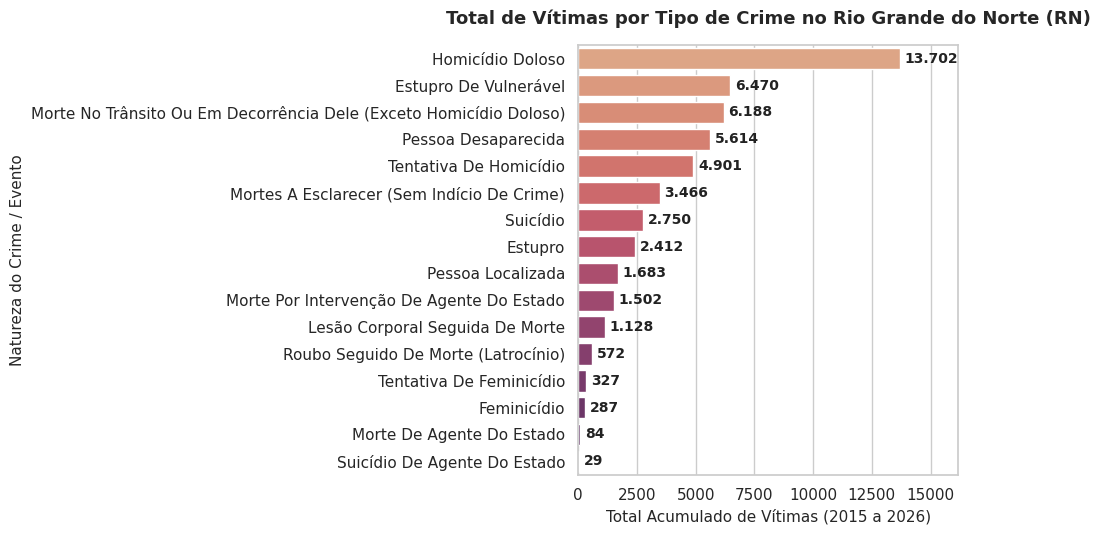

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

# Leitura otimizada por blocos com tipificação consistente
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"
colunas_interesse = ["uf", "evento", "total_vitima", "abrangencia"]
acumulador_rn = []

print("A processar dados de ocorrências por vítimas no RN...")
for chunk in pd.read_csv(caminho_csv, usecols=colunas_interesse, chunksize=100_000, low_memory=False):
    chunk_rn = chunk[
        (chunk["uf"].astype(str).str.strip().str.upper() == "RN") &
        (chunk["abrangencia"].astype(str).str.strip().str.lower() == "estadual")
    ].copy()

    if not chunk_rn.empty:
        chunk_rn["evento"] = chunk_rn["evento"].astype(str).str.strip().str.title()
        agrupado = chunk_rn.groupby("evento")["total_vitima"].sum().reset_index()
        acumulador_rn.append(agrupado)

df_rn = pd.concat(acumulador_rn, ignore_index=True)
df_rn = df_rn.groupby("evento")["total_vitima"].sum().reset_index()
df_rn["total_vitima"] = df_rn["total_vitima"].astype(int)
df_rn = df_rn[df_rn["total_vitima"] > 0].sort_values("total_vitima", ascending=False)

print("\n=== TOTAL DE VÍTIMAS POR CRIME NO RIO GRANDE DO NORTE (2015 A 2026) ===")
display(df_rn)

# Gráfico sem FutureWarning (atribuindo y a hue)
plt.figure(figsize=(10, 5.5))
ax = sns.barplot(
    data=df_rn,
    y="evento",
    x="total_vitima",
    hue="evento",
    palette="flare",
    legend=False
)

max_val = df_rn["total_vitima"].max()
for index, row in df_rn.reset_index(drop=True).iterrows():
    ax.text(
        row["total_vitima"] + (max_val * 0.015),
        index,
        f"{row['total_vitima']:,}".replace(",", "."),
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#222222"
    )

plt.title("Total de Vítimas por Tipo de Crime no Rio Grande do Norte (RN)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Total Acumulado de Vítimas (2015 a 2026)", fontsize=11)
plt.ylabel("Natureza do Crime / Evento", fontsize=11)
plt.xlim(0, max_val * 1.18)
plt.tight_layout()
plt.show()

In [ ]:
#==========================================
#==========================================
#LIMPEZA
#==========================================
#==========================================

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import hashlib
from pathlib import Path

sns.set_theme(style="whitegrid")

PASTA_SAIDA = Path("/content/resultados_cp1")
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"
caminho_estadual = PASTA_SAIDA / "sinesp_limpo_estadual.csv"
caminho_municipal = PASTA_SAIDA / "sinesp_limpo_municipal.csv"
caminho_relatorio = PASTA_SAIDA / "relatorio_limpeza.csv"
caminho_banco_hash = PASTA_SAIDA / "controle_duplicatas.sqlite"

# Colunas removidas com base no diagnóstico do CP1: mais de 99% de ausência.
# A remoção é registrada para manter a decisão transparente.
colunas_esparsas = ["total_peso", "faixa_etaria"]

# O banco SQLite permite controlar duplicatas entre lotes sem carregar
# milhões de identificadores simultaneamente na memória.
if caminho_banco_hash.exists():
    caminho_banco_hash.unlink()
con = sqlite3.connect(caminho_banco_hash)
con.execute("CREATE TABLE hashes_vistos (hash TEXT PRIMARY KEY)")
con.execute("CREATE TEMP TABLE hashes_lote (hash TEXT PRIMARY KEY, posicao INTEGER)")

# Reinicia os arquivos de saída para que a célula possa ser executada novamente.
for caminho in [caminho_estadual, caminho_municipal, caminho_relatorio]:
    if caminho.exists():
        caminho.unlink()

colunas_saida = None
primeira_escrita = {"estadual": True, "municipal": True}
contagem = {
    "linhas_lidas": 0,
    "estadual_antes_deduplicacao": 0,
    "municipal_antes_deduplicacao": 0,
    "estadual_gravadas": 0,
    "municipal_gravadas": 0,
    "duplicatas_removidas": 0,
    "datas_invalidas": 0,
    "vitimas_ausentes_ou_invalidas": 0,
    "vitimas_negativas": 0,
    "linhas_com_algum_valor_ausente": 0
}
relatorio_ausencia = {}

print("Iniciando limpeza em lotes...")

for numero_lote, chunk in enumerate(
    pd.read_csv(caminho_csv, chunksize=100_000, low_memory=False), start=1
):
    contagem["linhas_lidas"] += len(chunk)

    # Padronização de campos textuais, preservando valores ausentes como ausentes.
    for coluna in ["abrangencia", "uf", "evento", "municipio", "agente", "arma"]:
        if coluna in chunk.columns:
            chunk[coluna] = chunk[coluna].astype("string").str.strip()

    if "abrangencia" in chunk.columns:
        chunk["abrangencia"] = chunk["abrangencia"].str.lower()
    if "uf" in chunk.columns:
        chunk["uf"] = chunk["uf"].str.upper()
    if "evento" in chunk.columns:
        chunk["evento"] = chunk["evento"].str.title()
    if "municipio" in chunk.columns:
        chunk["municipio"] = chunk["municipio"].str.title()

    # Remoção justificada das variáveis muito esparsas identificadas no CP1.
    presentes_esparsas = [c for c in colunas_esparsas if c in chunk.columns]
    chunk = chunk.drop(columns=presentes_esparsas)

    # Converte data e quantidade sem transformar ausência em zero.
    if "data_referencia" in chunk.columns:
        data_convertida = pd.to_datetime(chunk["data_referencia"], errors="coerce")
        contagem["datas_invalidas"] += int(data_convertida.isna().sum())
        chunk["data_referencia"] = data_convertida.dt.strftime("%Y-%m-%d")
        chunk["ano"] = data_convertida.dt.year.astype("Int64")

    if "total_vitima" in chunk.columns:
        vitimas = pd.to_numeric(chunk["total_vitima"], errors="coerce")
        contagem["vitimas_ausentes_ou_invalidas"] += int(vitimas.isna().sum())
        contagem["vitimas_negativas"] += int((vitimas < 0).sum())
        chunk["total_vitima"] = vitimas

    contagem["linhas_com_algum_valor_ausente"] += int(chunk.isna().any(axis=1).sum())
    for coluna in chunk.columns:
        ausentes = int(chunk[coluna].isna().sum())
        relatorio_ausencia[coluna] = relatorio_ausencia.get(coluna, 0) + ausentes

    # Chave de deduplicação baseada nos dados substantivos; campos de origem
    # são excluídos para que a mesma ocorrência em arquivos/abas diferentes
    # também seja reconhecida como duplicata.
    colunas_chave = [c for c in chunk.columns if c not in ["arquivo_origem", "aba_origem"]]
    valores_hash = pd.util.hash_pandas_object(chunk[colunas_chave], index=False).astype("uint64")
    hashes = valores_hash.map(lambda x: hashlib.sha256(str(int(x)).encode()).hexdigest())

    con.execute("DELETE FROM hashes_lote")
    con.executemany(
        "INSERT OR IGNORE INTO hashes_lote(hash, posicao) VALUES (?, ?)",
        [(h, int(i)) for i, h in enumerate(hashes)]
    )
    # Identifica os hashes ainda não vistos antes de inseri-los na tabela global.
    novos = pd.read_sql_query(
        "SELECT h.posicao FROM hashes_lote h "
        "LEFT JOIN hashes_vistos v ON h.hash = v.hash "
        "WHERE v.hash IS NULL ORDER BY h.posicao", con
    )["posicao"].tolist()
    con.execute(
        "INSERT OR IGNORE INTO hashes_vistos(hash) SELECT hash FROM hashes_lote"
    )
    contagem["duplicatas_removidas"] += len(chunk) - len(novos)
    chunk = chunk.iloc[novos].copy()

    # Mantém duas bases para não descartar os registros municipais.
    if "abrangencia" not in chunk.columns:
        raise KeyError("A coluna 'abrangencia' não foi encontrada na base.")

    for nivel, nome_nivel, caminho in [
        ("estadual", "estadual", caminho_estadual),
        ("municipal", "municipal", caminho_municipal)
    ]:
        parte = chunk[chunk["abrangencia"] == nivel].copy()
        if parte.empty:
            continue

        contagem[f"{nome_nivel}_gravadas"] += len(parte)
        parte.to_csv(
            caminho,
            mode="w" if primeira_escrita[nome_nivel] else "a",
            header=primeira_escrita[nome_nivel],
            index=False,
            encoding="utf-8-sig"
        )
        primeira_escrita[nome_nivel] = False

    if numero_lote % 10 == 0:
        print(f"Lotes processados: {numero_lote} | Linhas lidas: {contagem['linhas_lidas']:,}")

con.close()

# Relatórios finais de qualidade e limpeza.
relatorio_final = pd.DataFrame(
    [{"indicador": chave, "quantidade": valor} for chave, valor in contagem.items()]
)
relatorio_final.to_csv(caminho_relatorio, index=False, encoding="utf-8-sig")

print("\nLimpeza concluída.")
print(f"Linhas lidas: {contagem['linhas_lidas']:,}")
print(f"Duplicatas removidas: {contagem['duplicatas_removidas']:,}")
print(f"Registros estaduais gravados: {contagem['estadual_gravadas']:,}")
print(f"Registros municipais gravados: {contagem['municipal_gravadas']:,}")
print(f"Datas ausentes/inválidas: {contagem['datas_invalidas']:,}")
print(f"Total de vítimas ausente/inválido: {contagem['vitimas_ausentes_ou_invalidas']:,}")
print(f"Total de vítimas negativas: {contagem['vitimas_negativas']:,}")

display(relatorio_final)

# Percentual de ausência por coluna na base lida. A proporção é calculada
# sobre o total de linhas de entrada, não apenas sobre um lote.
df_ausencia_final = pd.DataFrame([
    {
        "coluna": coluna,
        "valores_ausentes": quantidade,
        "percentual_ausente": round(quantidade / contagem["linhas_lidas"] * 100, 2)
        if contagem["linhas_lidas"] else 0
    }
    for coluna, quantidade in relatorio_ausencia.items()
]).sort_values("percentual_ausente", ascending=False)

display(df_ausencia_final)
df_ausencia_final.to_csv(
    PASTA_SAIDA / "relatorio_ausencia_pos_limpeza.csv",
    index=False,
    encoding="utf-8-sig"
)


Iniciando limpeza em lotes...
Lotes processados: 10 | Linhas lidas: 1,000,000
Lotes processados: 20 | Linhas lidas: 2,000,000
Lotes processados: 30 | Linhas lidas: 3,000,000
Lotes processados: 40 | Linhas lidas: 4,000,000
Lotes processados: 50 | Linhas lidas: 5,000,000
Lotes processados: 60 | Linhas lidas: 6,000,000
Lotes processados: 70 | Linhas lidas: 7,000,000
Lotes processados: 80 | Linhas lidas: 8,000,000
Lotes processados: 90 | Linhas lidas: 9,000,000

Limpeza concluída.
Linhas lidas: 9,170,708
Duplicatas removidas: 74,766
Registros estaduais gravados: 7,994,634
Registros municipais gravados: 0
Datas ausentes/inválidas: 0
Total de vítimas ausente/inválido: 1,189,049
Total de vítimas negativas: 0


,indicador,quantidade
0,linhas_lidas,9170708
1,estadual_antes_deduplicacao,0
2,municipal_antes_deduplicacao,0
3,estadual_gravadas,7994634
4,municipal_gravadas,0
5,duplicatas_removidas,74766
6,datas_invalidas,0
7,vitimas_ausentes_ou_invalidas,1189049
8,vitimas_negativas,0
9,linhas_com_algum_valor_ausente,9170708


,coluna,valores_ausentes,percentual_ausente
4,agente,9102998,99.26
5,arma,9102776,99.26
10,total,8282007,90.31
6,feminino,1631116,17.79
7,masculino,1626088,17.73
8,nao_informado,1598083,17.43
9,total_vitima,1189049,12.97
3,data_referencia,0,0.00
0,uf,0,0.00
1,municipio,0,0.00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
from pathlib import Path

sns.set_theme(style="whitegrid")

# Diretório onde foram salvas as bases após a limpeza
PASTA = Path("/content/resultados_cp1")

# Bases estadual e municipal
arquivo_estadual = PASTA / "sinesp_limpo_estadual.csv"
arquivo_municipal = PASTA / "sinesp_limpo_municipal.csv"

# Pasta para salvar os resultados da análise exploratória
PASTA_EDA = PASTA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)


# Função para padronizar textos
def padronizar_texto(serie):
    return serie.astype("string").str.strip().replace("", pd.NA)


# Função para remover acentos e padronizar nomes
def normalizar_nome(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).strip().lower()
    return unicodedata.normalize("NFKD", texto).encode(
        "ascii", errors="ignore"
    ).decode("utf-8")


# Carregando a base estadual
df = pd.read_csv(arquivo_estadual, low_memory=False)

# Filtrando apenas o Rio Grande do Norte
df_rn = df[
    df["uf"].astype(str).str.strip().str.upper() == "RN"
].copy()

# Preparando as datas
df_rn["data_referencia"] = pd.to_datetime(
    df_rn["data_referencia"],
    errors="coerce",
    dayfirst=True
)

df_rn["ano"] = df_rn["data_referencia"].dt.year
df_rn["mes"] = df_rn["data_referencia"].dt.month

# Preparando a quantidade de vítimas
df_rn["total_vitima"] = pd.to_numeric(
    df_rn["total_vitima"],
    errors="coerce"
)

# Valores negativos não são considerados nas somas
df_rn.loc[df_rn["total_vitima"] < 0, "total_vitima"] = np.nan

print("Quantidade de registros do RN:", len(df_rn))
print("Período analisado:",
      df_rn["ano"].min(), "até", df_rn["ano"].max())


Quantidade de registros do RN: 241226
Período analisado: 2015 até 2026


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import unicodedata
from pathlib import Path

# Garantir a criação da pasta de imagens
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. Filtro exato dos crimes oficiais para evitar falsos positivos
crimes_exatos = [
    "Estupro",
    "Estupro De Vulnerável",
    "Feminicídio",
    "Homicídio Doloso",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte No Trânsito Ou Em Decorrência Dele (Exceto Homicídio Culposo)",
    "Morte Por Intervenção De Agente Do Estado",
    "Suicídio"
]

# df_rn já está na memória após a execução da sua Célula 10
df_rn_selecao = df_rn[df_rn["evento"].isin(crimes_exatos)].copy()

# Remover registros onde o município não foi especificado
df_rn_filtrado = df_rn_selecao[
    ~df_rn_selecao["municipio"].str.contains("Não Informado|Nao Informado", case=False, na=False)
]

print(f"Base de seleção criada com sucesso! Total de registros validados: {len(df_rn_selecao)}")

Base de seleção criada com sucesso! Total de registros validados: 118029


In [ ]:



#==========================================================================================================================================================================================================
#CHECKPOINT 3
#==========================================================================================================================================================================================================




In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#BRASIL X RN
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

--- VALIDAÇÃO COM O PAINEL DO MJSP (RN) ---


,ano,total_vitima
11,2026,764
10,2025,1009
9,2024,842
8,2023,1050
7,2022,1239
6,2021,1315
5,2020,1505
4,2019,1459
3,2018,1982
2,2017,2428


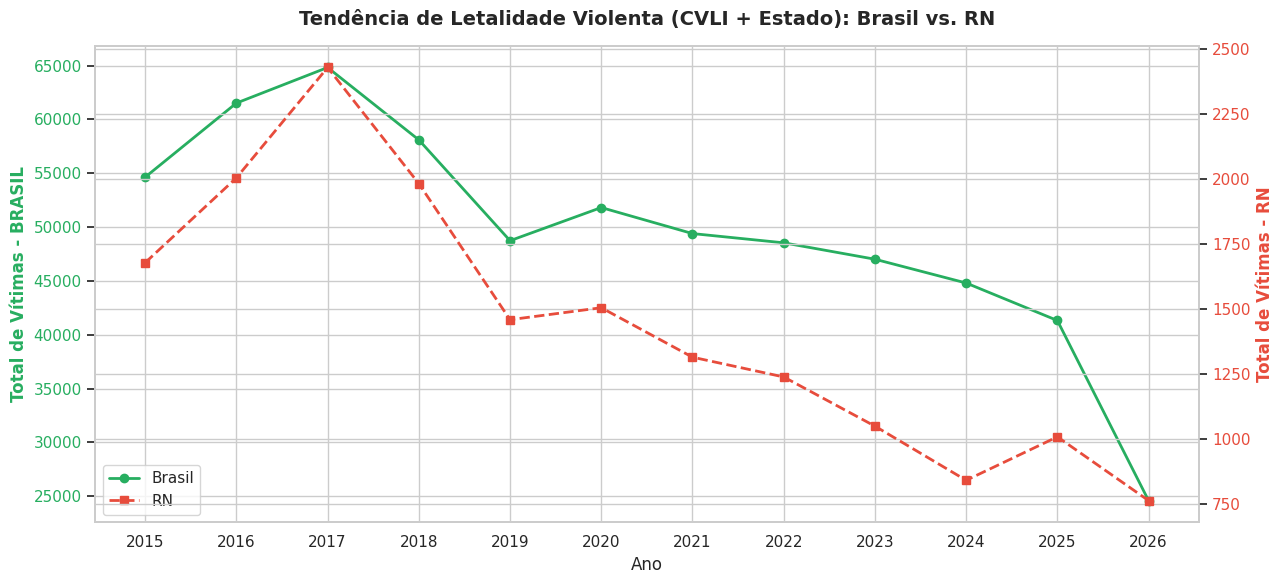

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. CARREGAR E PREPARAR A BASE COMPLETA
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"

# Lemos apenas as colunas necessárias para economizar memória
colunas = ["data_referencia", "evento", "total_vitima", "abrangencia", "uf"]
df_completo = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

# Filtro estrito: apenas abrangência Estadual (evita contar o município e o estado ao mesmo tempo)
df_estado = df_completo[df_completo["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()

df_estado["ano"] = pd.to_datetime(df_estado["data_referencia"], errors="coerce").dt.year
df_estado["total_vitima"] = pd.to_numeric(df_estado["total_vitima"], errors="coerce")
df_estado.loc[df_estado["total_vitima"] < 0, "total_vitima"] = np.nan
df_estado["evento"] = df_estado["evento"].astype(str).str.strip().str.title()
df_estado["uf"] = df_estado["uf"].astype(str).str.strip().str.upper()

# ==========================================
# 2. FILTRO EXATO: CVLI + LETALIDADE DO ESTADO
# ==========================================
crimes_mjsp = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Aplica o filtro na base geral
df_cvli = df_estado[df_estado["evento"].isin(crimes_mjsp)].copy()

# ==========================================
# 3. VALIDAÇÃO DOS DADOS DO RN (Ground Truth)
# ==========================================
df_cvli_rn = df_cvli[df_cvli["uf"] == "RN"]

vitimas_rn_ano = (
    df_cvli_rn.dropna(subset=["ano", "total_vitima"])
    .groupby("ano")["total_vitima"]
    .sum()
    .reset_index()
)
vitimas_rn_ano["ano"] = vitimas_rn_ano["ano"].astype(int)
vitimas_rn_ano["total_vitima"] = vitimas_rn_ano["total_vitima"].astype(int)

print("--- VALIDAÇÃO COM O PAINEL DO MJSP (RN) ---")
display(vitimas_rn_ano.sort_values(by="ano", ascending=False).head(11))

# ==========================================
# 4. AGRUPAMENTO DO BRASIL PARA COMPARAÇÃO
# ==========================================
vitimas_brasil_ano = (
    df_cvli.dropna(subset=["ano", "total_vitima"])
    .groupby("ano")["total_vitima"]
    .sum()
    .reset_index()
)
vitimas_brasil_ano["ano"] = vitimas_brasil_ano["ano"].astype(int)

# ==========================================
# 5. GRÁFICO COMPARATIVO: BRASIL VS. RN
# ==========================================
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(13, 6))

# Eixo Esquerdo: Brasil (Verde)
cor_br = '#27ae60'
ax1.set_xlabel('Ano', fontsize=12)
ax1.set_ylabel('Total de Vítimas - BRASIL', color=cor_br, fontsize=12, fontweight='bold')
ax1.plot(
    vitimas_brasil_ano['ano'],
    vitimas_brasil_ano['total_vitima'],
    color=cor_br,
    marker='o',
    linewidth=2,
    label='Brasil',
)
ax1.tick_params(axis='y', labelcolor=cor_br)
plt.xticks(vitimas_brasil_ano['ano'].astype(int))

# Eixo Direito: RN (Vermelho)
ax2 = ax1.twinx()
cor_rn = '#e74c3c'  # Vermelho
ax2.set_ylabel('Total de Vítimas - RN', color=cor_rn, fontsize=12, fontweight='bold')
ax2.plot(
    vitimas_rn_ano['ano'],
    vitimas_rn_ano['total_vitima'],
    color=cor_rn,
    marker='s',
    linewidth=2,
    linestyle='--',
    label='RN',
)
ax2.tick_params(axis='y', labelcolor=cor_rn)

# Adicionar legendas conjuntas
linhas1, rotulos1 = ax1.get_legend_handles_labels()
linhas2, rotulos2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, rotulos1 + rotulos2, loc='lower left')

plt.title(
    'Tendência de Letalidade Violenta (CVLI + Estado): Brasil vs. RN',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
fig.tight_layout()

# Salvar a imagem
PASTA_EDA = Path('/content/resultados_cp1/analise_exploratoria_RN')
PASTA_EDA.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_EDA / '13_comparativo_tendencia_cvli_rn_brasil.png')
plt.show()

In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#ESTADOS MAIS VIOLENTOS
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

,UF,total_vitima,populacao,taxa_por_100k
0,AP,344.0,733759,46.881878
1,BA,5477.0,14141626,38.729634
2,CE,3226.0,8794959,36.680103
3,PE,3153.0,9058931,34.805431
4,AL,1059.0,3127683,33.858930
5,RO,493.0,1581196,31.178930
6,PA,2513.0,8121025,30.944370
7,MA,2090.0,6775805,30.845044
8,RN,1009.0,3302729,30.550493
9,RJ,4471.0,16054524,27.848848


/tmp/ipykernel_4766/3891810363.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_ranking, x="taxa_por_100k", y="UF", palette="Reds_r", legend=False)


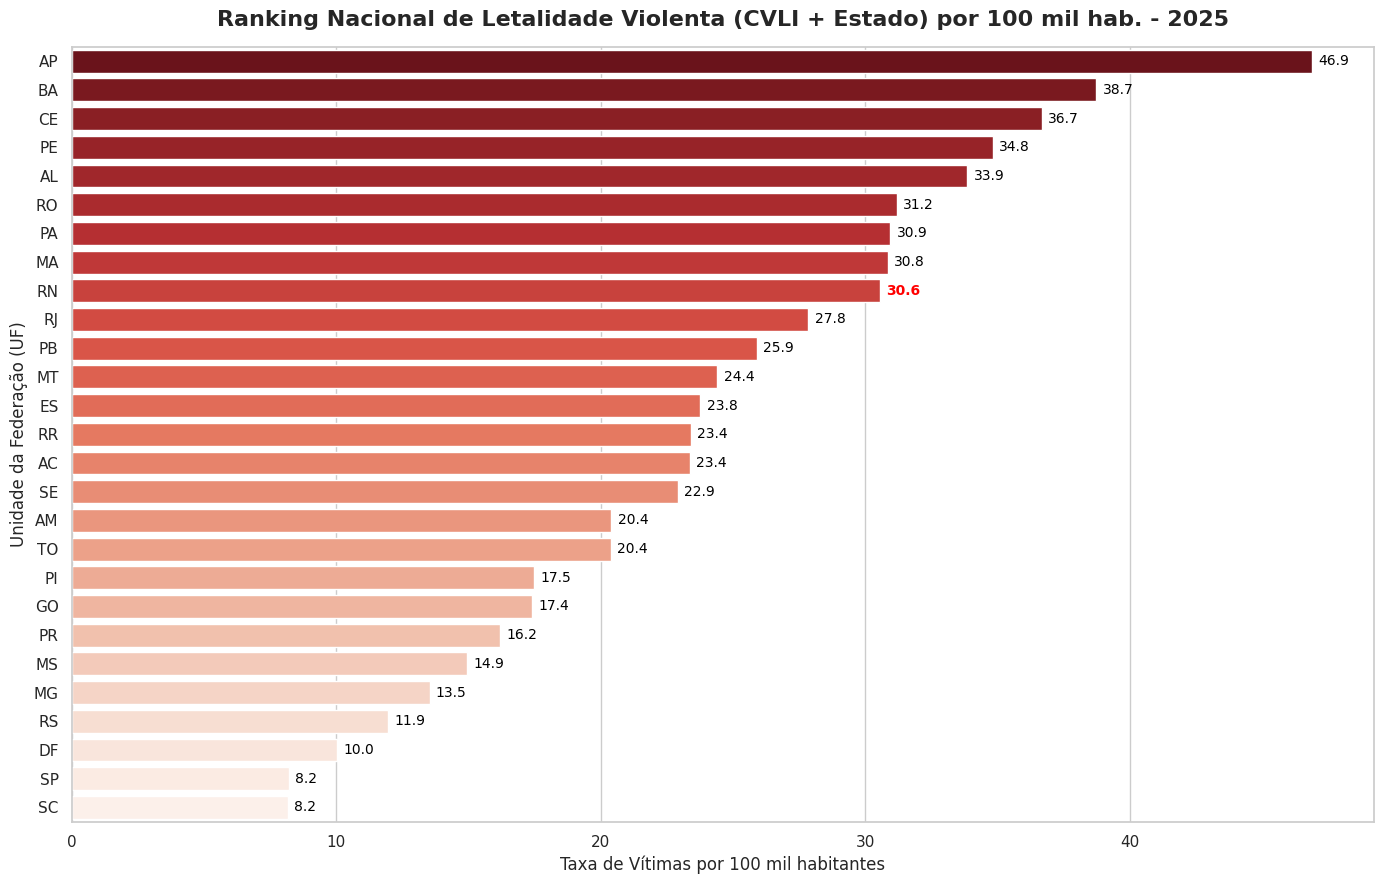

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. POPULAÇÃO DOS ESTADOS (Censo 2022 - IBGE)
# ==========================================
# Dicionário estático para evitar queda da API
populacao_estados = {
    'UF': ['SP', 'MG', 'RJ', 'BA', 'PR', 'RS', 'PE', 'CE', 'PA', 'SC', 'GO', 'MA',
           'PB', 'AM', 'ES', 'MT', 'RN', 'PI', 'AL', 'DF', 'MS', 'SE', 'RO', 'TO', 'AC', 'AP', 'RR'],
    'populacao': [44411238, 20538718, 16054524, 14141626, 11444380, 10882965, 9058931, 8794959,
                  8121025, 7610361, 7056495, 6775805, 3974687, 3941613, 3833712, 3658649, 3302729,
                  3271199, 3127683, 2817381, 2757013, 2209558, 1581196, 1511460, 830018, 733759, 636707]
}
df_pop_estados = pd.DataFrame(populacao_estados)

# ==========================================
# 2. CARREGAR E FILTRAR A BASE (Foco em 2025)
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"

# Carregar apenas as colunas vitais
colunas = ["data_referencia", "evento", "total_vitima", "abrangencia", "uf"]
df_completo = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

# Filtro 1: Apenas Estadual e padronização das colunas
df_est = df_completo[df_completo["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()
df_est["ano"] = pd.to_datetime(df_est["data_referencia"], errors="coerce").dt.year
df_est["total_vitima"] = pd.to_numeric(df_est["total_vitima"], errors="coerce")
df_est.loc[df_est["total_vitima"] < 0, "total_vitima"] = np.nan
df_est["evento"] = df_est["evento"].astype(str).str.strip().str.title()
df_est["uf"] = df_est["uf"].astype(str).str.strip().str.upper()

# Filtro 2: Apenas CVLI + Estado
crimes_cvli_estado = [
    "Homicídio Doloso", "Feminicídio", "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte", "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Filtro 3: Aplicar seleção de crimes e focar APENAS NO ANO DE 2025
df_2025 = df_est[(df_est["evento"].isin(crimes_cvli_estado)) & (df_est["ano"] == 2025)].copy()

# ==========================================
# 3. AGRUPAMENTO E NORMALIZAÇÃO POR 100k
# ==========================================
# Somar vítimas por UF no ano de 2025
vitimas_por_estado = df_2025.groupby("uf")["total_vitima"].sum().reset_index()
vitimas_por_estado.rename(columns={"uf": "UF"}, inplace=True)

# Cruzar (Merge) com a tabela de população
df_ranking = pd.merge(vitimas_por_estado, df_pop_estados, on="UF", how="inner")

# Calcular a taxa por 100 mil habitantes
df_ranking["taxa_por_100k"] = (df_ranking["total_vitima"] / df_ranking["populacao"]) * 100000

# Ordenar do mais violento para o mais seguro
df_ranking = df_ranking.sort_values(by="taxa_por_100k", ascending=False).reset_index(drop=True)

display(df_ranking)

# ==========================================
# 4. GRÁFICO DO RANKING NACIONAL
# ==========================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 9))

# Paleta "Reds_r" (vermelho escuro no topo, clareando pra baixo)
ax = sns.barplot(data=df_ranking, x="taxa_por_100k", y="UF", palette="Reds_r", legend=False)

plt.title("Ranking Nacional de Letalidade Violenta (CVLI + Estado) por 100 mil hab. - 2025",
          fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Taxa de Vítimas por 100 mil habitantes", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os valores exatos na ponta de cada barra
max_val = df_ranking["taxa_por_100k"].max()
for index, row in df_ranking.iterrows():
    # Destaca o RN no gráfico de barras
    peso_fonte = 'bold' if row["UF"] == 'RN' else 'normal'
    cor_fonte = 'red' if row["UF"] == 'RN' else 'black'

    ax.text(row["taxa_por_100k"] + (max_val * 0.005),
            index,
            f'{row["taxa_por_100k"]:.1f}',
            va="center",
            fontsize=10,
            fontweight=peso_fonte,
            color=cor_fonte)

plt.tight_layout()

# Salvar a imagem
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_EDA / "14_ranking_nacional_cvli_100k_2025.png")
plt.show()

,UF,total_vitima,populacao,taxa_por_100k
0,AP,4575.0,733759,623.501722
1,RN,17275.0,3302729,523.052300
2,AL,16173.0,3127683,517.092045
3,BA,72058.0,14141626,509.545366
4,PA,39820.0,8121025,490.332193
5,PE,44265.0,9058931,488.633813
6,SE,10738.0,2209558,485.979549
7,CE,41954.0,8794959,477.023258
8,RJ,65340.0,16054524,406.988086
9,AC,3287.0,830018,396.015508


/tmp/ipykernel_4766/1596443481.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_ranking, x="taxa_por_100k", y="UF", palette="Reds_r", legend=False)


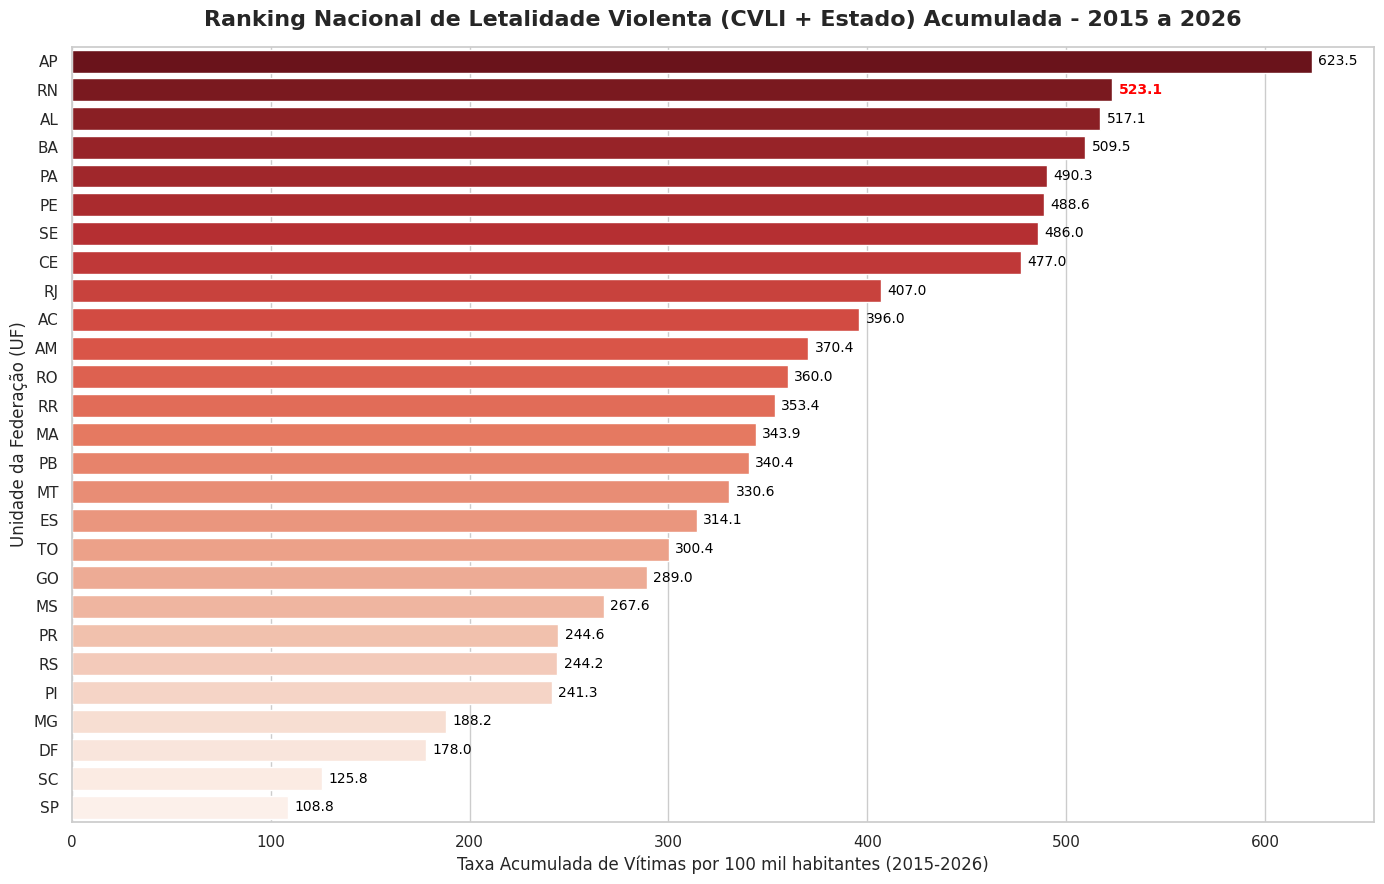

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. POPULAÇÃO DOS ESTADOS (Censo 2022 - IBGE)
# ==========================================
populacao_estados = {
    'UF': ['SP', 'MG', 'RJ', 'BA', 'PR', 'RS', 'PE', 'CE', 'PA', 'SC', 'GO', 'MA',
           'PB', 'AM', 'ES', 'MT', 'RN', 'PI', 'AL', 'DF', 'MS', 'SE', 'RO', 'TO', 'AC', 'AP', 'RR'],
    'populacao': [44411238, 20538718, 16054524, 14141626, 11444380, 10882965, 9058931, 8794959,
                  8121025, 7610361, 7056495, 6775805, 3974687, 3941613, 3833712, 3658649, 3302729,
                  3271199, 3127683, 2817381, 2757013, 2209558, 1581196, 1511460, 830018, 733759, 636707]
}
df_pop_estados = pd.DataFrame(populacao_estados)

# ==========================================
# 2. CARREGAR E FILTRAR A BASE (Período 2015 a 2026)
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"

colunas = ["data_referencia", "evento", "total_vitima", "abrangencia", "uf"]
df_completo = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

# Filtro 1: Apenas Estadual e padronização das colunas
df_est = df_completo[df_completo["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()
df_est["ano"] = pd.to_datetime(df_est["data_referencia"], errors="coerce").dt.year
df_est["total_vitima"] = pd.to_numeric(df_est["total_vitima"], errors="coerce")
df_est.loc[df_est["total_vitima"] < 0, "total_vitima"] = np.nan
df_est["evento"] = df_est["evento"].astype(str).str.strip().str.title()
df_est["uf"] = df_est["uf"].astype(str).str.strip().str.upper()

# Filtro 2: Apenas CVLI + Estado
crimes_cvli_estado = [
    "Homicídio Doloso", "Feminicídio", "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte", "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Filtro 3: Aplicar seleção de crimes e focar NO PERÍODO DE 2015 A 2026
df_periodo = df_est[(df_est["evento"].isin(crimes_cvli_estado)) & (df_est["ano"] >= 2015) & (df_est["ano"] <= 2026)].copy()

# ==========================================
# 3. AGRUPAMENTO E NORMALIZAÇÃO POR 100k
# ==========================================
# Somar vítimas por UF no período total
vitimas_por_estado = df_periodo.groupby("uf")["total_vitima"].sum().reset_index()
vitimas_por_estado.rename(columns={"uf": "UF"}, inplace=True)

# Cruzar (Merge) com a tabela de população
df_ranking = pd.merge(vitimas_por_estado, df_pop_estados, on="UF", how="inner")

# Calcular a taxa por 100 mil habitantes (Acumulada)
df_ranking["taxa_por_100k"] = (df_ranking["total_vitima"] / df_ranking["populacao"]) * 100000

# Ordenar do mais violento para o mais seguro
df_ranking = df_ranking.sort_values(by="taxa_por_100k", ascending=False).reset_index(drop=True)

display(df_ranking)

# ==========================================
# 4. GRÁFICO DO RANKING NACIONAL (2015-2026)
# ==========================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 9))

# Paleta "Reds_r" (vermelho escuro no topo, clareando pra baixo)
ax = sns.barplot(data=df_ranking, x="taxa_por_100k", y="UF", palette="Reds_r", legend=False)

plt.title("Ranking Nacional de Letalidade Violenta (CVLI + Estado) Acumulada - 2015 a 2026",
          fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Taxa Acumulada de Vítimas por 100 mil habitantes (2015-2026)", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os valores exatos na ponta de cada barra
max_val = df_ranking["taxa_por_100k"].max()
for index, row in df_ranking.iterrows():
    # Destaca o RN no gráfico de barras
    peso_fonte = 'bold' if row["UF"] == 'RN' else 'normal'
    cor_fonte = 'red' if row["UF"] == 'RN' else 'black'

    ax.text(row["taxa_por_100k"] + (max_val * 0.005),
            index,
            f'{row["taxa_por_100k"]:.1f}',
            va="center",
            fontsize=10,
            fontweight=peso_fonte,
            color=cor_fonte)

plt.tight_layout()

# Salvar a imagem
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_EDA / "14_ranking_nacional_cvli_100k_acumulado_2015_2026.png")
plt.show()

In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#DADOS DO RN
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

--- TOP 15 MUNICÍPIOS (NÚMEROS ABSOLUTOS) ---


,municipio,total_vitima
0,Natal,3447
1,Mossoró,1848
2,Parnamirim,852
3,São Gonçalo Do Amarante,761
4,Macaíba,684
5,Ceará-Mirim,515
6,São José De Mipibu,436
7,Extremoz,334
8,Açu,260
9,Nísia Floresta,258


/tmp/ipykernel_4766/1349266612.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


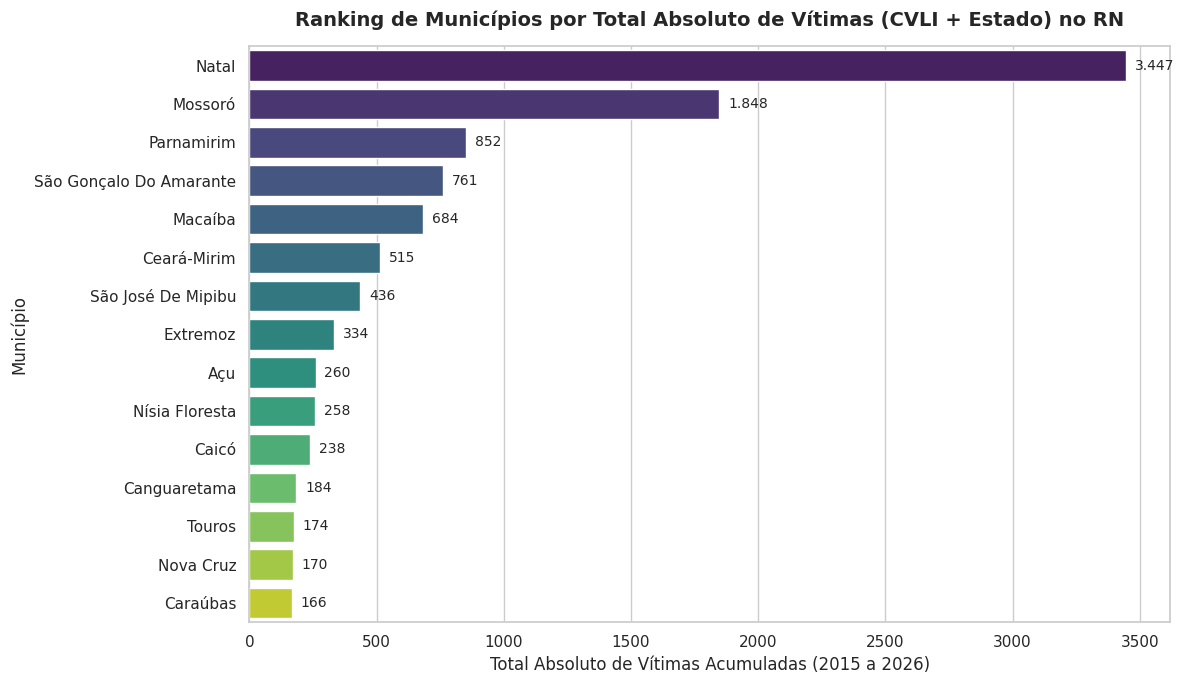

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. CARREGAR E PREPARAR A BASE DO RN
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
arquivo_rn = PASTA_SAIDA / "sinesp_limpo_estadual.csv"

# Carrega a base e filtra o RN
df_rn = pd.read_csv(arquivo_rn, low_memory=False)
df_rn = df_rn[df_rn["uf"].astype(str).str.strip().str.upper() == "RN"].copy()

# Tratamento básico de tipos e textos
df_rn["total_vitima"] = pd.to_numeric(df_rn["total_vitima"], errors="coerce")
df_rn.loc[df_rn["total_vitima"] < 0, "total_vitima"] = np.nan
df_rn["municipio"] = df_rn["municipio"].astype(str).str.strip().str.title()
df_rn["evento"] = df_rn["evento"].astype(str).str.strip().str.title()

# ==========================================
# 2. FILTRO EXATO: CVLI + ESTADO
# ==========================================
crimes_cvli_estado = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Filtrar a base apenas para os crimes letais violentos
df_cvli = df_rn[df_rn["evento"].isin(crimes_cvli_estado)].copy()

# ==========================================
# 3. AGRUPAMENTO ABSOLUTO POR MUNICÍPIO
# ==========================================
# Remover registros onde o município é "Não Informado"
df_cvli = df_cvli[~df_cvli["municipio"].str.contains("Não Informado|Nao Informado", case=False, na=False)]

# Agrupar e somar as vítimas por município
ranking_absoluto = (
    df_cvli.dropna(subset=["municipio", "total_vitima"])
    .groupby("municipio")["total_vitima"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
ranking_absoluto["total_vitima"] = ranking_absoluto["total_vitima"].astype(int)

print("--- TOP 15 MUNICÍPIOS (NÚMEROS ABSOLUTOS) ---")
display(ranking_absoluto.head(15))

# ==========================================
# 4. GRÁFICO DO RANKING ABSOLUTO
# ==========================================
plt.figure(figsize=(12, 7))

# Paleta "viridis" para diferenciar do gráfico de taxas (magma/reds)
ax = sns.barplot(
    data=ranking_absoluto.head(15),
    x="total_vitima",
    y="municipio",
    palette="viridis",
    legend=False
)

plt.title("Ranking de Municípios por Total Absoluto de Vítimas (CVLI + Estado) no RN", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Total Absoluto de Vítimas Acumuladas (2015 a 2026)", fontsize=12)
plt.ylabel("Município", fontsize=12)

# Colocando o número absoluto na ponta de cada barra
max_val = ranking_absoluto.head(15)["total_vitima"].max()
for index, row in ranking_absoluto.head(15).iterrows():
    ax.text(row["total_vitima"] + (max_val * 0.01),
            index,
            f'{row["total_vitima"]:,}'.replace(',', '.'),
            va="center",
            fontsize=10)

plt.tight_layout()

# Salvar a imagem
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_EDA / "15_ranking_absoluto_municipios_cvli.png")
plt.show()

,municipio,populacao,total_vitima,taxa_por_100k
0,Macaíba,82212,725.0,881.866394
1,Areia Branca,24093,191.0,792.761383
2,Mossoró,264577,2087.0,788.806283
3,São Gonçalo Do Amarante,115838,816.0,704.432052
4,Ceará-Mirim,79115,554.0,700.246477
5,Baraúna,27644,176.0,636.666184
6,Extremoz,61571,381.0,618.797811
7,Touros,33035,195.0,590.283033
8,Caicó,61146,344.0,562.587904
9,Natal,751300,4102.0,545.986956


/tmp/ipykernel_4766/3728311755.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


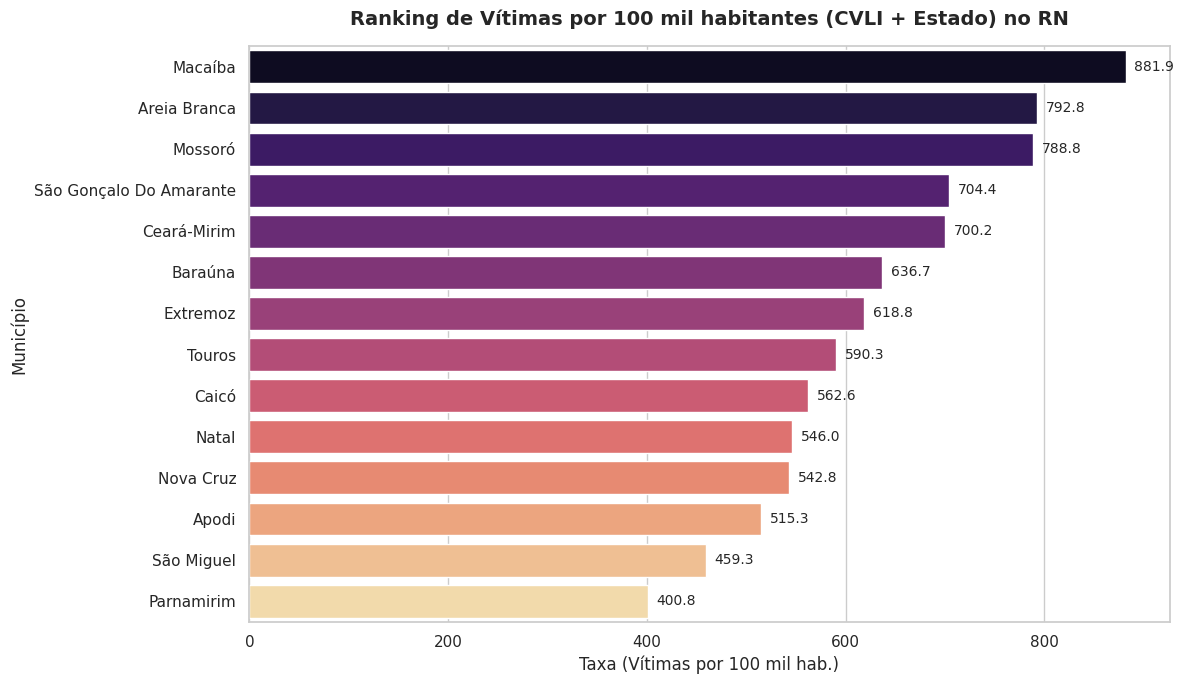

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# ==========================================
# 0. RECRIAR O RANKING DE MUNICÍPIOS
# ==========================================
# Remover registros onde o município é "Não Informado"
df_rn_filtrado = df_rn_selecao[
    ~df_rn_selecao["municipio"].str.contains("Não Informado|Nao Informado", case=False, na=False)
]

# Agrupar e somar as vítimas por município
ranking_municipios = (
    df_rn_filtrado.dropna(subset=["municipio", "total_vitima"])
    .groupby("municipio")["total_vitima"]
    .sum()
    .reset_index()
)

# ==========================================
# 1. DADOS DE POPULAÇÃO (Censo 2022 - IBGE)
# ==========================================
dados_populacao = {
    'municipio': [
        'Natal', 'Mossoró', 'Parnamirim', 'São Gonçalo Do Amarante',
        'Macaíba', 'Ceará-Mirim', 'Extremoz', 'Baraúna', 'Assu', 'Caicó',
        'Apodi', 'Areia Branca', 'Nova Cruz', 'São Miguel', 'Touros'
    ],
    'populacao': [
        751300, 264577, 252716, 115838,
        82212, 79115, 61571, 27644, 53227, 61146,
        36093, 24093, 34269, 23949, 33035
    ]
}
df_ibge = pd.DataFrame(dados_populacao)

def normalizar_nome(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).strip().lower()
    return unicodedata.normalize("NFKD", texto).encode("ascii", errors="ignore").decode("utf-8")

# Criar chaves normalizadas para cruzamento
df_ibge['municipio_chave'] = df_ibge['municipio'].apply(normalizar_nome)
ranking_municipios['municipio_chave'] = ranking_municipios['municipio'].apply(normalizar_nome)

# Cruzamento (Merge) Sinesp + IBGE
df_taxas = pd.merge(
    ranking_municipios,
    df_ibge[['municipio_chave', 'populacao']],
    on='municipio_chave',
    how='inner'
)

# ==========================================
# 2. CÁLCULO ESTATÍSTICO DA TAXA (100k)
# ==========================================
# Multiplicando por 100.000 para padronização oficial
df_taxas['taxa_por_100k'] = (df_taxas['total_vitima'] / df_taxas['populacao']) * 100000

# Ordenar do pior município (maior taxa) para o menor
df_taxas = df_taxas.sort_values(by='taxa_por_100k', ascending=False).reset_index(drop=True)

display(df_taxas[['municipio', 'populacao', 'total_vitima', 'taxa_por_100k']])

# ==========================================
# 3. GRÁFICO DA TAXA
# ==========================================
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=df_taxas,
    x="taxa_por_100k",
    y="municipio",
    palette="magma",
    legend=False
)

plt.title("Ranking de Vítimas por 100 mil habitantes (CVLI + Estado) no RN", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Taxa (Vítimas por 100 mil hab.)", fontsize=12)
plt.ylabel("Município", fontsize=12)

# Colocando o número da taxa flutuando na ponta de cada barra
max_val = df_taxas["taxa_por_100k"].max()
for index, row in df_taxas.iterrows():
    ax.text(row["taxa_por_100k"] + (max_val * 0.01),
            index,
            f'{row["taxa_por_100k"]:.1f}',
            va="center",
            fontsize=10)

plt.tight_layout()
plt.show()

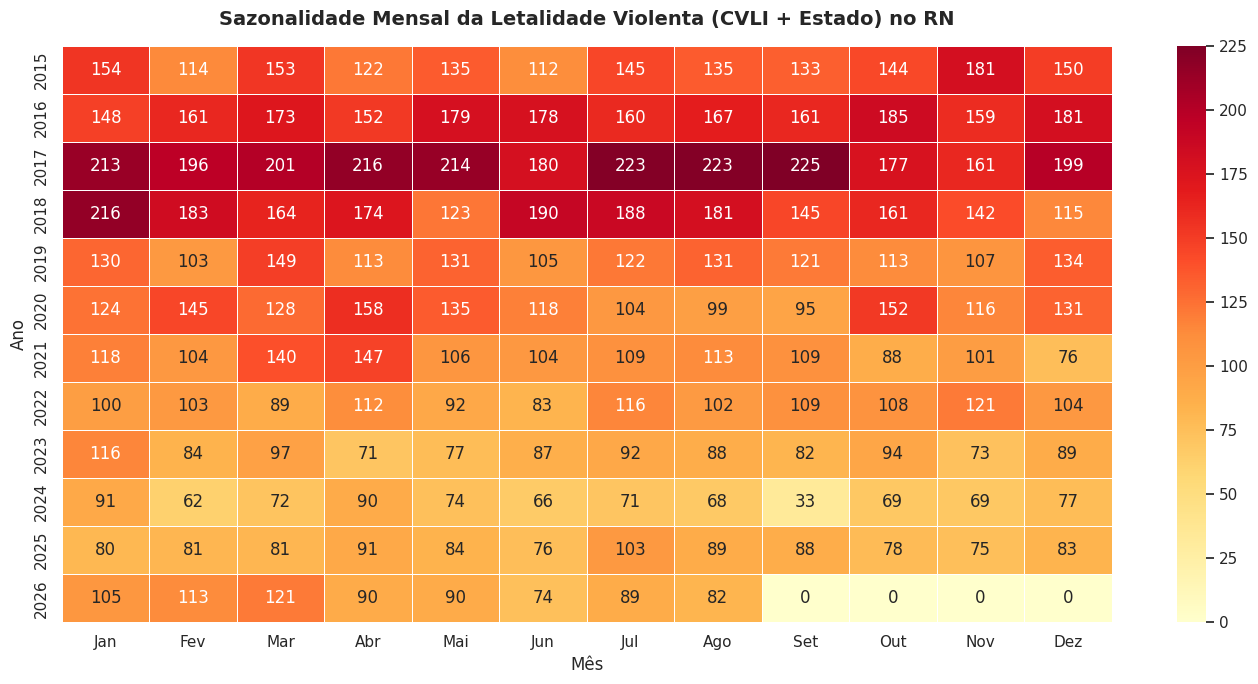

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Garantir o caminho da pasta para salvar a imagem
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. Definir estritamente os 2 grupos (CVLI + Estado)
crimes_cvli_estado = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# 2. Filtrar a base do RN (assumindo que df_rn já está na memória)
df_rn_cvli = df_rn[df_rn["evento"].isin(crimes_cvli_estado)].copy()

# Garantir que a coluna de data é do tipo datetime e criar as colunas 'mes' e 'ano'
df_rn_cvli["data_referencia"] = pd.to_datetime(df_rn_cvli["data_referencia"], errors="coerce")
df_rn_cvli["mes"] = df_rn_cvli["data_referencia"].dt.month
df_rn_cvli["ano"] = df_rn_cvli["data_referencia"].dt.year
df_rn_cvli["total_vitima"] = pd.to_numeric(df_rn_cvli["total_vitima"], errors="coerce")

# 3. Utilizar o dataframe filtrado para agrupar as vítimas mensais
vitimas_mensais = (
    df_rn_cvli.dropna(subset=["ano", "mes", "total_vitima"])
    .groupby(["ano", "mes"])["total_vitima"]
    .sum()
    .reset_index()
)
vitimas_mensais["ano"] = vitimas_mensais["ano"].astype(int)
vitimas_mensais["mes"] = vitimas_mensais["mes"].astype(int)

# 4. Transformar os dados em matriz (Pivot)
matriz_mensal = vitimas_mensais.pivot(
    index="ano",
    columns="mes",
    values="total_vitima"
).reindex(columns=range(1, 13)).fillna(0) # Garante que todos os 12 meses apareçam, mesmo se não houver registros

# Nomes dos meses para o eixo X
nomes_meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

# 5. Gerar o Gráfico de Calor (Heatmap)
plt.figure(figsize=(14, 7))

sns.heatmap(
    matriz_mensal,
    cmap="YlOrRd",    # Paleta amarelo-laranja-vermelho (ideal para indicar calor/risco)
    linewidths=0.5,
    xticklabels=nomes_meses,
    annot=True,       # Mostra os valores numéricos dentro do gráfico
    fmt=".0f"         # Remove casas decimais dos rótulos
)

plt.title("Sazonalidade Mensal da Letalidade Violenta (CVLI + Estado) no RN", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Ano", fontsize=12)

plt.tight_layout()
plt.savefig(PASTA_EDA / "06_sazonalidade_mensal_cvli_estado.png")
plt.show()

<Figure size 1200x700 with 0 Axes>

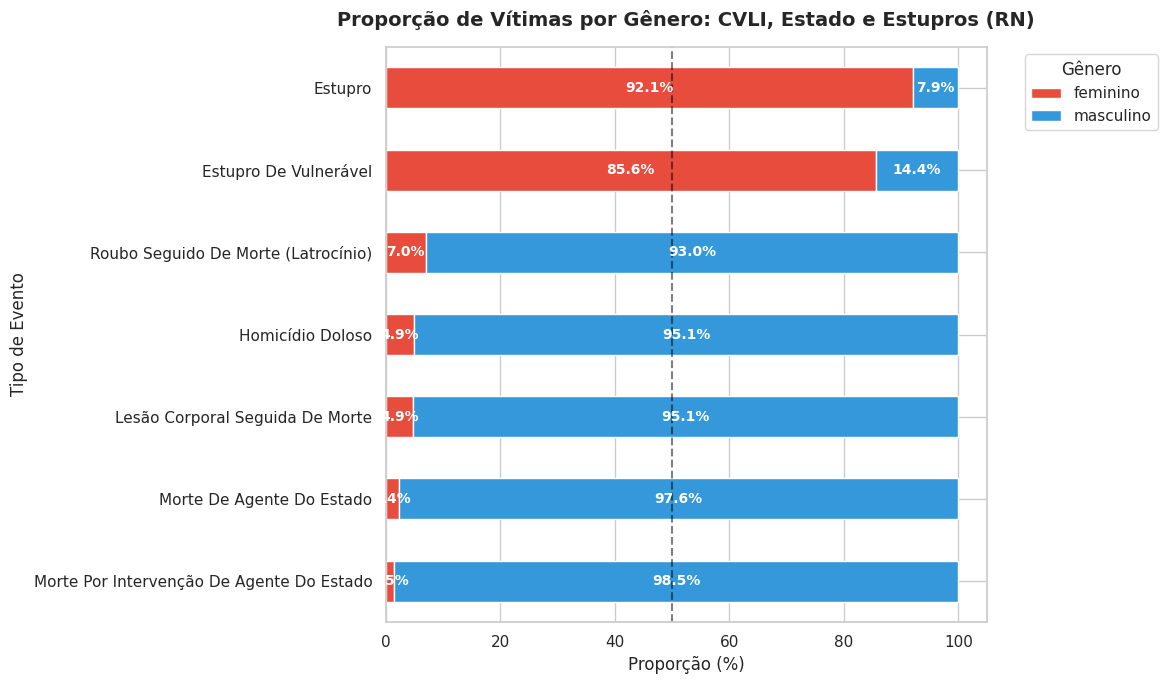

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Garantir o caminho da pasta
PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. Definir os crimes: Grupo 1 (CVLI - sem Feminicídio), Grupo 2 (Estado) e Estupros
crimes_foco = [
    "Homicídio Doloso",
    # "Feminicídio",  <-- Removido a pedido
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado",
    "Estupro",
    "Estupro De Vulnerável"
]

# Filtrar a base do RN apenas para esses crimes (assumindo que df_rn já está na memória)
df_foco = df_rn[df_rn['evento'].isin(crimes_foco)].copy()

# 2. Isolar as colunas de interesse
colunas_interesse = ['evento', 'feminino', 'masculino']
df_genero_crime = df_foco[colunas_interesse].copy()

# 3. Converter para numérico e tratar valores negativos
for col in ['feminino', 'masculino']:
    df_genero_crime[col] = pd.to_numeric(df_genero_crime[col], errors='coerce')
    df_genero_crime.loc[df_genero_crime[col] < 0, col] = 0

# 4. Agrupar por evento e somar
agrupamento_genero = df_genero_crime.groupby('evento').sum()

# Remover crimes que por acaso tenham 0 vítimas de ambos os gêneros (evita divisão por zero)
agrupamento_genero = agrupamento_genero[(agrupamento_genero['feminino'] > 0) | (agrupamento_genero['masculino'] > 0)]

# 5. Calcular proporção (percentual) para normalizar a visualização
agrupamento_genero_pct = agrupamento_genero.div(agrupamento_genero.sum(axis=1), axis=0) * 100

# Ordenar para o gráfico ficar mais organizado
agrupamento_genero_pct = agrupamento_genero_pct.sort_values(by='feminino', ascending=True)

# 6. Gráfico de Barras Empilhadas (100%)
plt.figure(figsize=(12, 7))
ax = agrupamento_genero_pct.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7),
    color=['#e74c3c', '#3498db'], # Vermelho (Feminino), Azul (Masculino)
    edgecolor='white'
)

plt.title("Proporção de Vítimas por Gênero: CVLI, Estado e Estupros (RN)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Proporção (%)", fontsize=12)
plt.ylabel("Tipo de Evento", fontsize=12)
plt.legend(title="Gênero", bbox_to_anchor=(1.05, 1), loc='upper left')

# Linha de referência no 50%
plt.axvline(50, color='black', linestyle='--', alpha=0.5)

# Adicionar as porcentagens dentro das barras
for c in ax.containers:
    labels = [f'{w:.1f}%' if w > 0 else '' for w in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(PASTA_EDA / "17_agrupamento_genero_foco_sem_feminicidio.png")
plt.show()

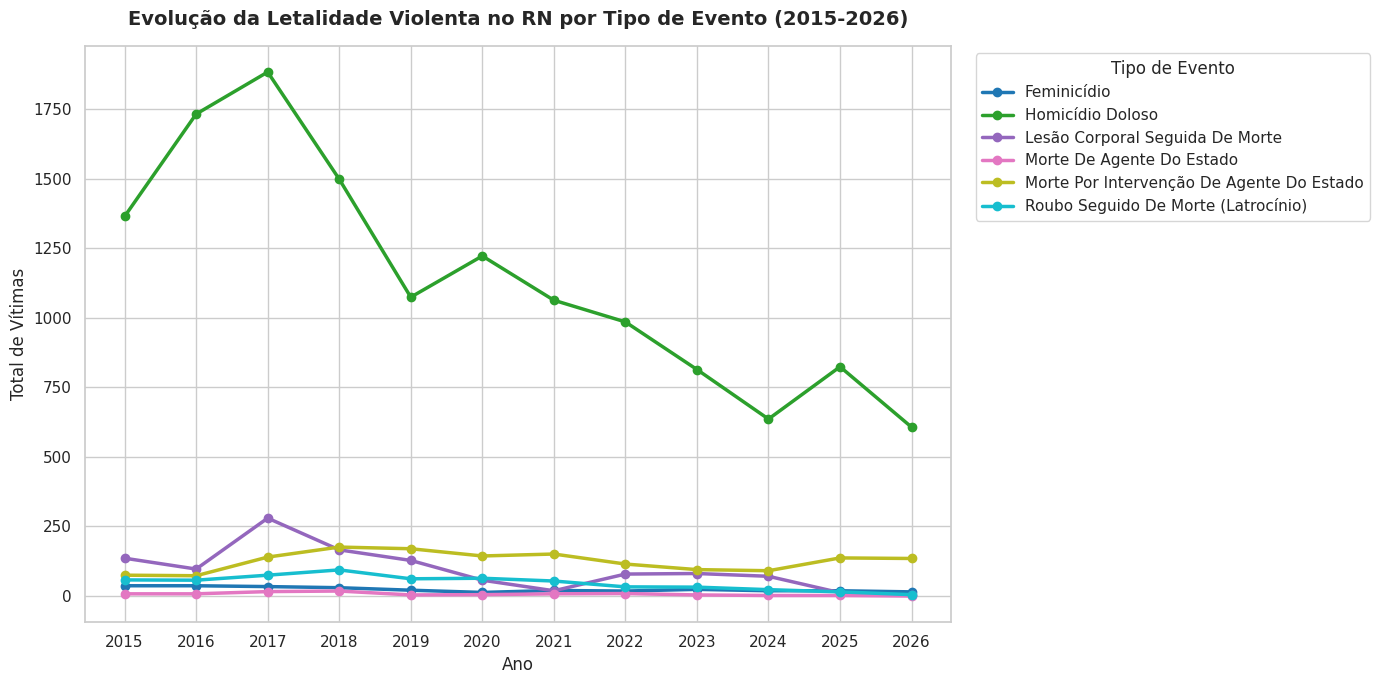

/tmp/ipykernel_4766/3372092609.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


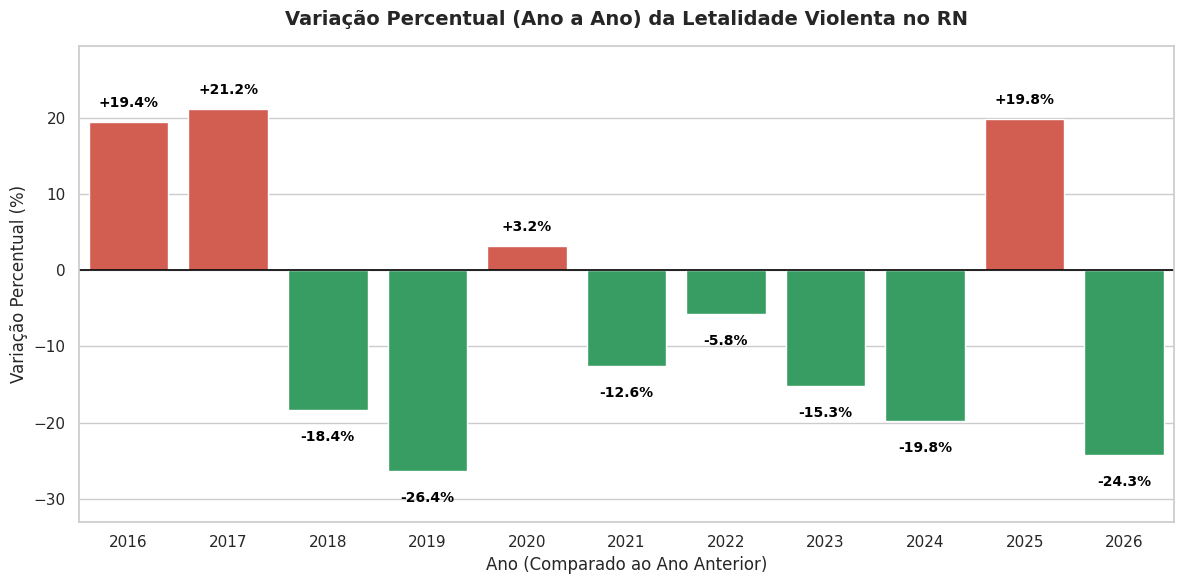

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 0. CONFIGURAÇÃO DE PASTAS E PREPARAÇÃO DA BASE
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# Lendo a base já limpa (focada no Estadual)
arquivo_rn = PASTA_SAIDA / "sinesp_limpo_estadual.csv"
df_rn = pd.read_csv(arquivo_rn, low_memory=False)

# Filtrar para RN
df_rn = df_rn[df_rn["uf"].astype(str).str.strip().str.upper() == "RN"].copy()

# Tratamento de campos
df_rn["ano"] = pd.to_datetime(df_rn["data_referencia"], errors="coerce").dt.year
df_rn["total_vitima"] = pd.to_numeric(df_rn["total_vitima"], errors="coerce")
df_rn.loc[df_rn["total_vitima"] < 0, "total_vitima"] = np.nan
df_rn["evento"] = df_rn["evento"].astype(str).str.strip().str.title()

# Filtro Exato de Letalidade (CVLI + Estado)
crimes_foco = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]
df_foco = df_rn[df_rn["evento"].isin(crimes_foco)].copy()

# ==========================================
# GRÁFICO 1: EVOLUÇÃO POR TIPO DE CRIME (GRÁFICO DE LINHAS)
# ==========================================
# 1. CRIAR A MATRIZ DE DADOS ANTES DE PLOTAR (Correção do Erro)
matriz_areas = (
    df_foco.dropna(subset=["ano", "total_vitima"])
    .groupby(["ano", "evento"])["total_vitima"]
    .sum()
    .unstack(fill_value=0)
)

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot do gráfico de linhas
matriz_areas.plot.line(
    ax=plt.gca(),
    marker='o',       # Adiciona marcadores (bolinhas) em cada ano
    linewidth=2.5,    # Deixa as linhas mais espessas
    cmap="tab10"      # Paleta de cores
)

plt.title("Evolução da Letalidade Violenta no RN por Tipo de Evento (2015-2026)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Ano", fontsize=12)
plt.ylabel("Total de Vítimas", fontsize=12)
plt.xticks(matriz_areas.index)

# Mover a legenda para fora da área do gráfico para não sobrepor os dados
plt.legend(title="Tipo de Evento", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig(PASTA_EDA / "18_composicao_interna_letalidade_linhas.png")
plt.show()

# ==========================================
# GRÁFICO 2: VARIAÇÃO PERCENTUAL ANO A ANO (BARRAS DIVERGENTES)
# ==========================================
# Agrupar o total geral por ano
total_anual = (
    df_foco.dropna(subset=["ano", "total_vitima"])
    .groupby("ano")["total_vitima"]
    .sum()
    .reset_index()
)
total_anual["ano"] = total_anual["ano"].astype(int)
total_anual = total_anual.sort_values("ano").reset_index(drop=True)

# Calcular a variação percentual (Δ%) em relação ao ano anterior
total_anual["variacao_pct"] = total_anual["total_vitima"].pct_change() * 100

# Descartar 2015 (pois não temos 2014 para comparar o crescimento inicial)
total_anual_var = total_anual.dropna(subset=["variacao_pct"]).copy()

# Definir a lógica de cores: Verde para queda (<=0), Vermelho para aumento (>0)
cores = ['#27ae60' if x <= 0 else '#e74c3c' for x in total_anual_var["variacao_pct"]]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=total_anual_var,
    x="ano",
    y="variacao_pct",
    palette=cores,
    legend=False
)

plt.title("Variação Percentual (Ano a Ano) da Letalidade Violenta no RN", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Ano (Comparado ao Ano Anterior)", fontsize=12)
plt.ylabel("Variação Percentual (%)", fontsize=12)
plt.axhline(0, color='black', linewidth=1.2) # Linha central do zero

# Adicionar os rótulos de porcentagem na ponta das barras
for index, row in enumerate(total_anual_var.itertuples()):
    valor = row.variacao_pct
    sinal = "+" if valor > 0 else ""
    # Ajusta a altura do texto dependendo se a barra vai para cima ou para baixo
    pos_y = valor + 2 if valor > 0 else valor - 4
    ax.text(index, pos_y, f"{sinal}{valor:.1f}%", color='black', ha="center", fontweight="bold", fontsize=10)

# Aumentar a margem vertical (limite Y) para o texto não ficar cortado
y_min, y_max = plt.ylim()
plt.ylim(y_min * 1.15, y_max * 1.25)

plt.tight_layout()
plt.savefig(PASTA_EDA / "19_variacao_percentual_yoy_letalidade.png")
plt.show()

/tmp/ipykernel_4766/4055402634.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


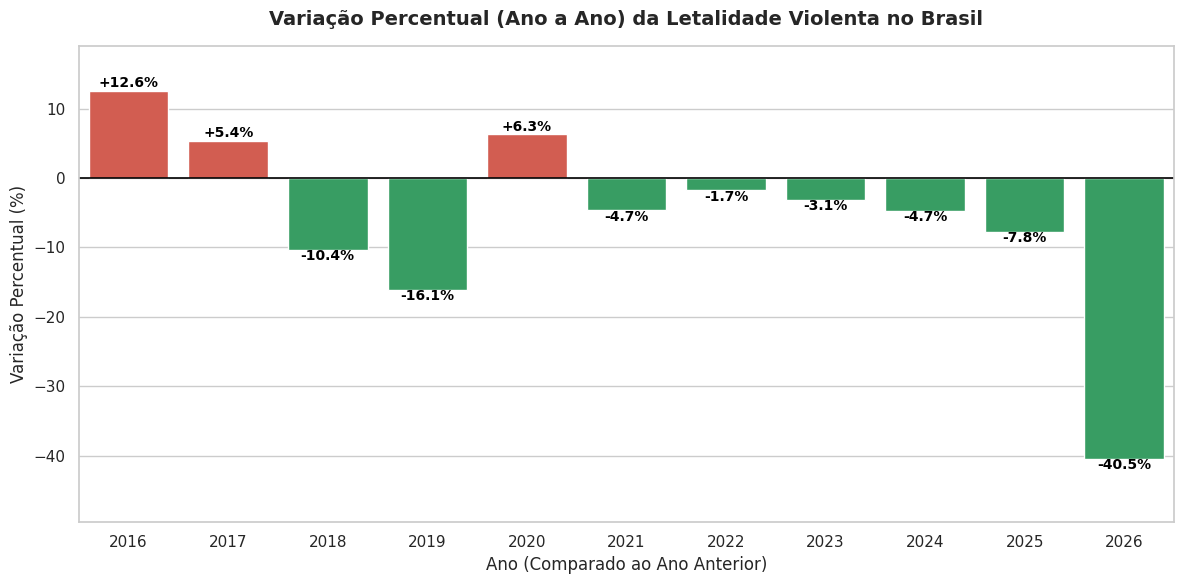

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. CARREGAR A BASE NACIONAL DA PASTA TEMPORÁRIA
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"

# Carregar as colunas necessárias (sem filtrar o estado)
colunas = ["data_referencia", "evento", "total_vitima", "abrangencia"]
df_completo = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

# Filtro 1: Apenas consolidação Estadual para não duplicar dados
df_br = df_completo[df_completo["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()

# Tratamento de datas e valores numéricos
df_br["ano"] = pd.to_datetime(df_br["data_referencia"], errors="coerce").dt.year
df_br["total_vitima"] = pd.to_numeric(df_br["total_vitima"], errors="coerce")
df_br.loc[df_br["total_vitima"] < 0, "total_vitima"] = np.nan
df_br["evento"] = df_br["evento"].astype(str).str.strip().str.title()

# Filtro 2: Exato de Letalidade (CVLI + Estado)
crimes_foco = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]
df_br_foco = df_br[df_br["evento"].isin(crimes_foco)].copy()

# ==========================================
# 2. CALCULAR A VARIAÇÃO PERCENTUAL (BRASIL)
# ==========================================
# Agrupar o total geral por ano somando todos os estados
total_anual_br = (
    df_br_foco.dropna(subset=["ano", "total_vitima"])
    .groupby("ano")["total_vitima"]
    .sum()
    .reset_index()
)
total_anual_br["ano"] = total_anual_br["ano"].astype(int)
total_anual_br = total_anual_br.sort_values("ano").reset_index(drop=True)

# Calcular a variação percentual (Δ%) em relação ao ano anterior
total_anual_br["variacao_pct"] = total_anual_br["total_vitima"].pct_change() * 100

# Descartar 2015 (pois não temos 2014 para comparar o crescimento inicial)
total_anual_var_br = total_anual_br.dropna(subset=["variacao_pct"]).copy()

# Definir a lógica de cores: Verde para queda (<=0), Vermelho para aumento (>0)
cores_br = ['#27ae60' if x <= 0 else '#e74c3c' for x in total_anual_var_br["variacao_pct"]]

# ==========================================
# 3. GRÁFICO (BARRAS DIVERGENTES)
# ==========================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=total_anual_var_br,
    x="ano",
    y="variacao_pct",
    palette=cores_br,
    legend=False
)

plt.title("Variação Percentual (Ano a Ano) da Letalidade Violenta no Brasil", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Ano (Comparado ao Ano Anterior)", fontsize=12)
plt.ylabel("Variação Percentual (%)", fontsize=12)
plt.axhline(0, color='black', linewidth=1.2) # Linha central do zero

# Adicionar os rótulos de porcentagem na ponta das barras
for index, row in enumerate(total_anual_var_br.itertuples()):
    valor = row.variacao_pct
    sinal = "+" if valor > 0 else ""
    # Ajusta a altura do texto dependendo se a barra vai para cima ou para baixo
    pos_y = valor + 0.5 if valor > 0 else valor - 1.5
    ax.text(index, pos_y, f"{sinal}{valor:.1f}%", color='black', ha="center", fontweight="bold", fontsize=10)

# Aumentar a margem vertical (limite Y) para o texto não ficar cortado
y_min, y_max = plt.ylim()
plt.ylim(y_min * 1.15, y_max * 1.25)

plt.tight_layout()

# Salvar a imagem
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_EDA / "29_variacao_percentual_yoy_letalidade_brasil.png")
plt.show()

/tmp/ipykernel_4766/3270869851.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


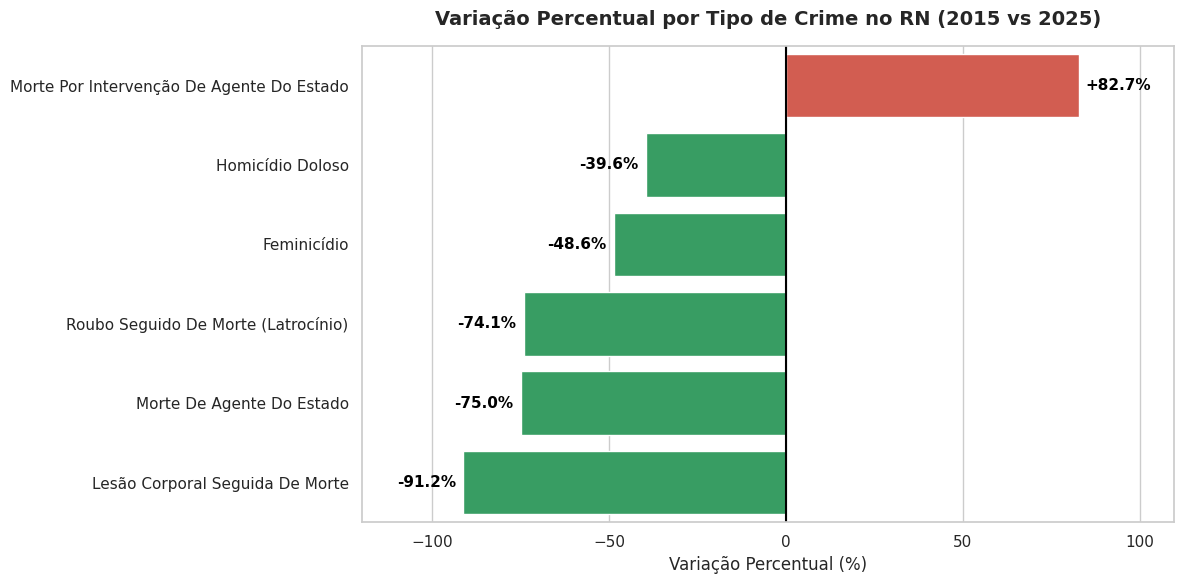

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 1. PREPARAR A BASE DO RN E FILTRAR CRIMES
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

arquivo_rn = PASTA_SAIDA / "sinesp_limpo_estadual.csv"
df_rn = pd.read_csv(arquivo_rn, low_memory=False)

# Filtro RN e tratamento de dados
df_rn = df_rn[df_rn["uf"].astype(str).str.strip().str.upper() == "RN"].copy()
df_rn["ano"] = pd.to_datetime(df_rn["data_referencia"], errors="coerce").dt.year
df_rn["total_vitima"] = pd.to_numeric(df_rn["total_vitima"], errors="coerce")
df_rn.loc[df_rn["total_vitima"] < 0, "total_vitima"] = np.nan
df_rn["evento"] = df_rn["evento"].astype(str).str.strip().str.title()

# Crimes Foco (Letalidade Violenta)
crimes_foco = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]
df_foco = df_rn[df_rn["evento"].isin(crimes_foco)].copy()

# ==========================================
# 2. CALCULAR A VARIAÇÃO PERCENTUAL (2015 vs 2025)
# ==========================================
# Agrupar vítimas por ano e evento
vitimas_ano_crime = (
    df_foco.dropna(subset=["ano", "total_vitima"])
    .groupby(["ano", "evento"])["total_vitima"]
    .sum()
    .unstack(fill_value=0) # Transforma os crimes em colunas
)

# Definir os anos de comparação (2015 como base, 2025 como final completo)
ano_inicial = 2015
ano_final = 2025

# Calcular a variação percentual
# Fórmula: ((Valor Final - Valor Inicial) / Valor Inicial) * 100
variacao = (
    ((vitimas_ano_crime.loc[ano_final] - vitimas_ano_crime.loc[ano_inicial])
     / vitimas_ano_crime.loc[ano_inicial].replace(0, np.nan)) * 100
).reset_index()

variacao.columns = ["evento", "variacao_pct"]

# Tratar possíveis casos onde o ano inicial era 0 (gera infinito)
variacao["variacao_pct"] = variacao["variacao_pct"].fillna(0)

# Ordenar do maior aumento (positivo) para a maior queda (negativo)
variacao = variacao.sort_values("variacao_pct", ascending=False).reset_index(drop=True)

# ==========================================
# 3. GRÁFICO DE BARRAS DIVERGENTES
# ==========================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Definir cores: Vermelho para aumento (> 0), Verde para queda (<= 0)
cores = ['#e74c3c' if x > 0 else '#27ae60' for x in variacao["variacao_pct"]]

ax = sns.barplot(
    data=variacao,
    x="variacao_pct",
    y="evento",
    palette=cores,
    legend=False
)

plt.title(f"Variação Percentual por Tipo de Crime no RN ({ano_inicial} vs {ano_final})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Variação Percentual (%)", fontsize=12)
plt.ylabel("", fontsize=12)
plt.axvline(0, color='black', linewidth=1.5) # Eixo central do zero

# Ajustar o limite do eixo X para caber os rótulos perfeitamente
x_min, x_max = plt.xlim()
plt.xlim(x_min * 1.2, x_max * 1.2)

# Adicionar os rótulos de porcentagem na ponta das barras
for index, row in enumerate(variacao.itertuples()):
    valor = row.variacao_pct
    sinal = "+" if valor > 0 else ""

    # Ajustar posição do texto (à direita se positivo, à esquerda se negativo)
    alinhamento = "left" if valor > 0 else "right"
    offset = (x_max * 0.02) if valor > 0 else -(abs(x_min) * 0.02)

    ax.text(valor + offset,
            index,
            f"{sinal}{valor:.1f}%",
            color='black',
            va="center",
            ha=alinhamento,
            fontweight="bold",
            fontsize=11)

plt.tight_layout()
plt.savefig(PASTA_EDA / "21_variacao_crimes_2015_2025.png")
plt.show()

In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#LETALIDADE POLÍCIA POR ESTADO
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

/tmp/ipykernel_4766/382557931.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=agrupado_agentes, x='taxa_100k', y='uf', palette='Reds_r', legend=False)


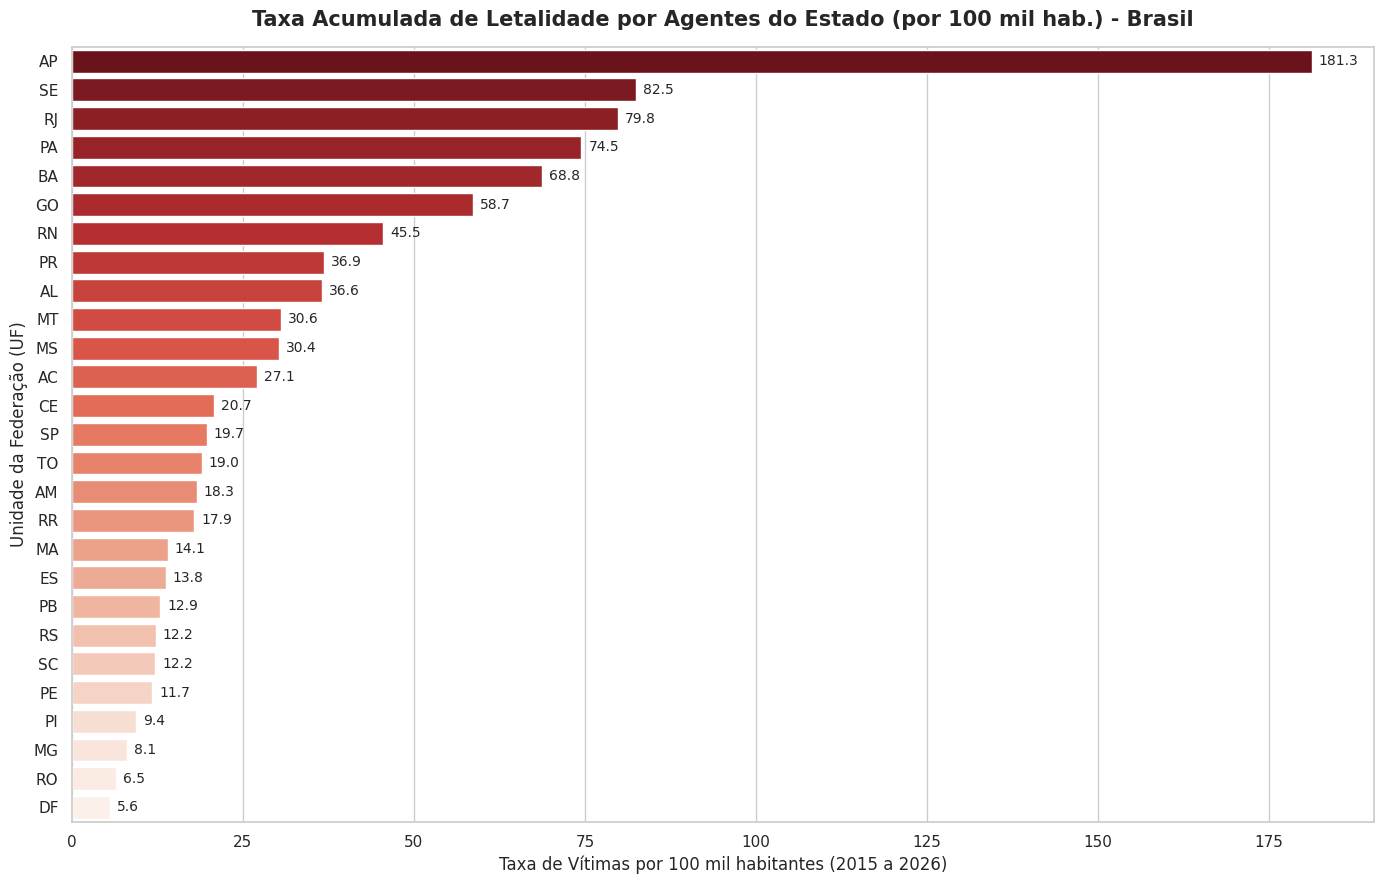

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. CARREGAR A BASE ESTADUAL
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"
colunas = ["data_referencia", "evento", "total_vitima", "abrangencia", "uf"]
df_br = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

df_br_est = df_br[df_br["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()
df_br_est["total_vitima"] = pd.to_numeric(df_br_est["total_vitima"], errors="coerce").fillna(0)
df_br_est["evento"] = df_br_est["evento"].astype(str).str.strip().str.title()
df_br_est["uf"] = df_br_est["uf"].astype(str).str.strip().str.upper()

# Dicionário de População por UF (Censo IBGE 2022) para cálculo da taxa
dict_pop_uf = {
    'SP': 44411238, 'MG': 20538718, 'RJ': 16054524, 'BA': 14141626, 'PR': 11444380,
    'RS': 10882965, 'PE': 9058931, 'CE': 8794957, 'PA': 8121025, 'SC': 7610361,
    'GO': 7056495, 'MA': 6775805, 'PB': 3974687, 'AM': 3941613, 'ES': 3833712,
    'MT': 3658649, 'RN': 3302729, 'PI': 3271199, 'AL': 3127683, 'DF': 2817381,
    'MS': 2757013, 'SE': 2209558, 'RO': 1581196, 'TO': 1511460, 'AC': 830018,
    'AP': 733759, 'RR': 636227
}

df_br_est['populacao'] = df_br_est['uf'].map(dict_pop_uf)

# 2. FILTRAR LETALIDADE POLICIAL
df_agentes = df_br_est[df_br_est["evento"] == "Morte Por Intervenção De Agente Do Estado"].copy()

# Agrupar total de vítimas por UF
agrupado_agentes = df_agentes.groupby(['uf', 'populacao'])['total_vitima'].sum().reset_index()

# Calcular a taxa de letalidade policial por 100 mil habitantes
agrupado_agentes['taxa_100k'] = (agrupado_agentes['total_vitima'] / agrupado_agentes['populacao']) * 100000
agrupado_agentes = agrupado_agentes.sort_values('taxa_100k', ascending=False)

# 3. GRÁFICO
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

ax = sns.barplot(data=agrupado_agentes, x='taxa_100k', y='uf', palette='Reds_r', legend=False)

plt.title("Taxa Acumulada de Letalidade por Agentes do Estado (por 100 mil hab.) - Brasil", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Taxa de Vítimas por 100 mil habitantes (2015 a 2026)", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os rótulos nas barras
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', padding=5, fontsize=10)

plt.tight_layout()
plt.savefig(PASTA_EDA / "24_letalidade_agentes_estado_uf.png", bbox_inches='tight')
plt.show()

/tmp/ipykernel_4766/357176604.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=agrupado_agentes, x='taxa_100k', y='uf', palette='Reds_r', legend=False)


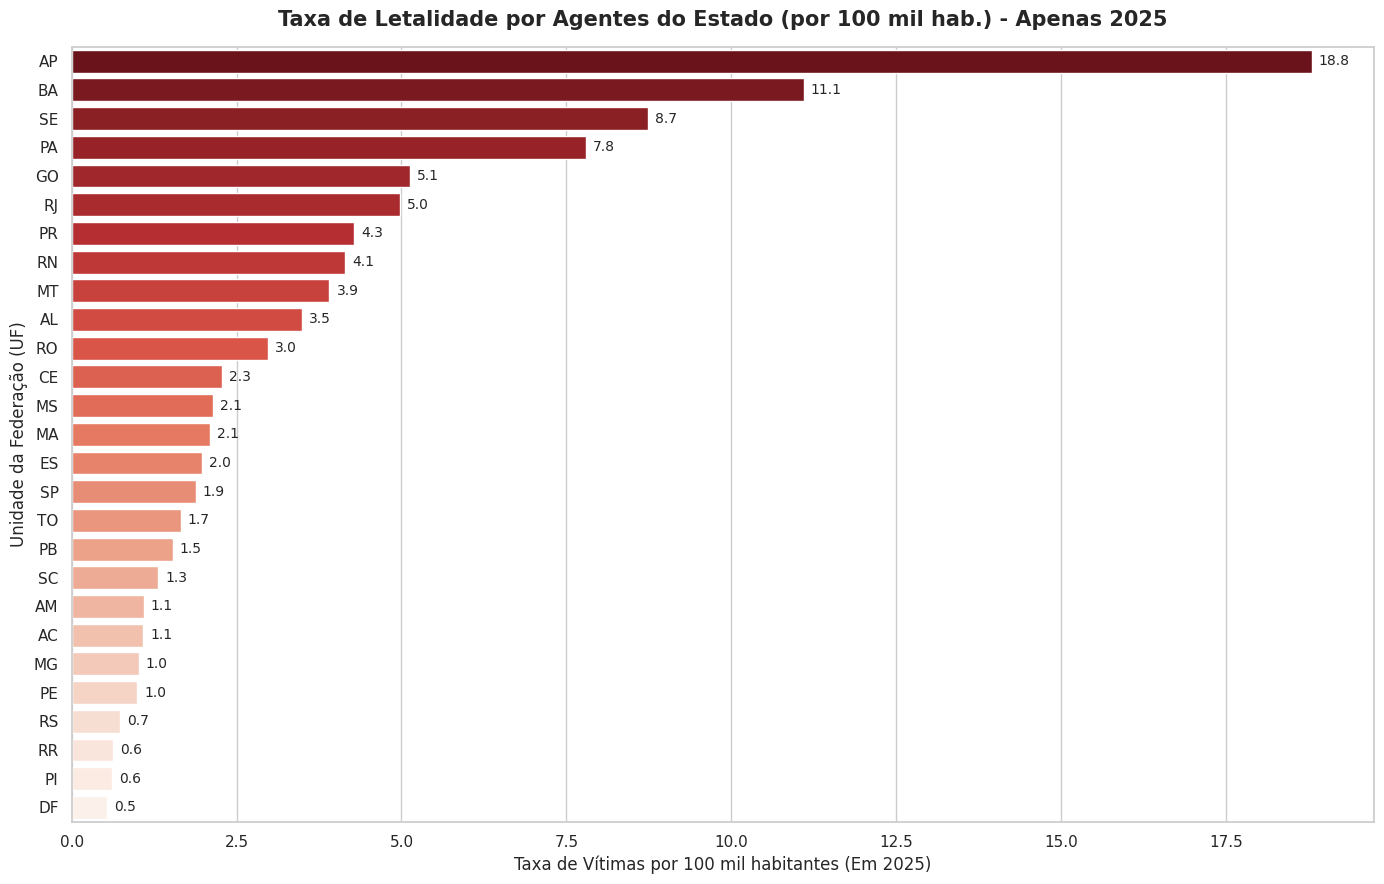

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. CARREGAR A BASE ESTADUAL
caminho_csv = PASTA_SAIDA / "sinesp_consolidado.csv"
# NOTA: Se der erro de arquivo não encontrado, troque o caminho_csv para ler do seu Drive:
# caminho_csv = Path('/content/drive/MyDrive/Dados_SINESP_CP1/sinesp_consolidado.csv')

colunas = ["data_referencia", "evento", "total_vitima", "abrangencia", "uf"]
df_br = pd.read_csv(caminho_csv, usecols=colunas, low_memory=False)

df_br_est = df_br[df_br["abrangencia"].astype(str).str.strip().str.lower() == "estadual"].copy()

# -------------------------------------------------------------
# NOVO PASSO: Extrair o ano e filtrar apenas para 2025
# -------------------------------------------------------------
df_br_est["ano"] = pd.to_datetime(df_br_est["data_referencia"], errors="coerce").dt.year
df_br_est = df_br_est[df_br_est["ano"] == 2025].copy()

df_br_est["total_vitima"] = pd.to_numeric(df_br_est["total_vitima"], errors="coerce").fillna(0)
df_br_est["evento"] = df_br_est["evento"].astype(str).str.strip().str.title()
df_br_est["uf"] = df_br_est["uf"].astype(str).str.strip().str.upper()

# Dicionário de População por UF (Censo IBGE 2022) para cálculo da taxa
dict_pop_uf = {
    'SP': 44411238, 'MG': 20538718, 'RJ': 16054524, 'BA': 14141626, 'PR': 11444380,
    'RS': 10882965, 'PE': 9058931, 'CE': 8794957, 'PA': 8121025, 'SC': 7610361,
    'GO': 7056495, 'MA': 6775805, 'PB': 3974687, 'AM': 3941613, 'ES': 3833712,
    'MT': 3658649, 'RN': 3302729, 'PI': 3271199, 'AL': 3127683, 'DF': 2817381,
    'MS': 2757013, 'SE': 2209558, 'RO': 1581196, 'TO': 1511460, 'AC': 830018,
    'AP': 733759, 'RR': 636227
}

df_br_est['populacao'] = df_br_est['uf'].map(dict_pop_uf)

# 2. FILTRAR LETALIDADE POLICIAL
df_agentes = df_br_est[df_br_est["evento"] == "Morte Por Intervenção De Agente Do Estado"].copy()

# Agrupar total de vítimas por UF
agrupado_agentes = df_agentes.groupby(['uf', 'populacao'])['total_vitima'].sum().reset_index()

# Calcular a taxa de letalidade policial por 100 mil habitantes
agrupado_agentes['taxa_100k'] = (agrupado_agentes['total_vitima'] / agrupado_agentes['populacao']) * 100000
agrupado_agentes = agrupado_agentes.sort_values('taxa_100k', ascending=False)

# 3. GRÁFICO
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

ax = sns.barplot(data=agrupado_agentes, x='taxa_100k', y='uf', palette='Reds_r', legend=False)

# Título e Eixos atualizados para focar exclusivamente em 2025
plt.title("Taxa de Letalidade por Agentes do Estado (por 100 mil hab.) - Apenas 2025", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Taxa de Vítimas por 100 mil habitantes (Em 2025)", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os rótulos nas barras
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', padding=5, fontsize=10)

plt.tight_layout()
plt.savefig(PASTA_EDA / "28_letalidade_agentes_estado_uf_2025.png", bbox_inches='tight')
plt.show()

In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#CRIMES X IDHM
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

In [ ]:
from pathlib import Path

nome_arquivo_ibge = "bba6318174ce758f501d590704c5f324.csv"

# Procura o arquivo a partir de /content (ou da pasta atual se /content não existir)
base_busca = Path("/content") if Path("/content").exists() else Path(".")
candidatos = list(base_busca.rglob(nome_arquivo_ibge))

if candidatos:
  arquivo_ibge = candidatos[0]
  print(f"Arquivo encontrado em: {arquivo_ibge}")
else:
  # Se estiver no Google Colab e não foi encontrado, abre o seletor de upload
  try:
    from google.colab import files

    print(
        "Arquivo não encontrado no ambiente. Faça o upload do CSV do IBGE:"
    )
    uploaded = files.upload()
    arquivo_ibge = Path(list(uploaded.keys())[0])
  except ImportError:
    raise FileNotFoundError(
        f"Não foi possível localizar '{nome_arquivo_ibge}'. Verifique o"
        " caminho ou coloque o arquivo na mesma pasta do script."
    )

Arquivo encontrado em: /content/bba6318174ce758f501d590704c5f324.csv


Total de Cidades Processadas: 167


/tmp/ipykernel_4766/3421882831.py:121: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


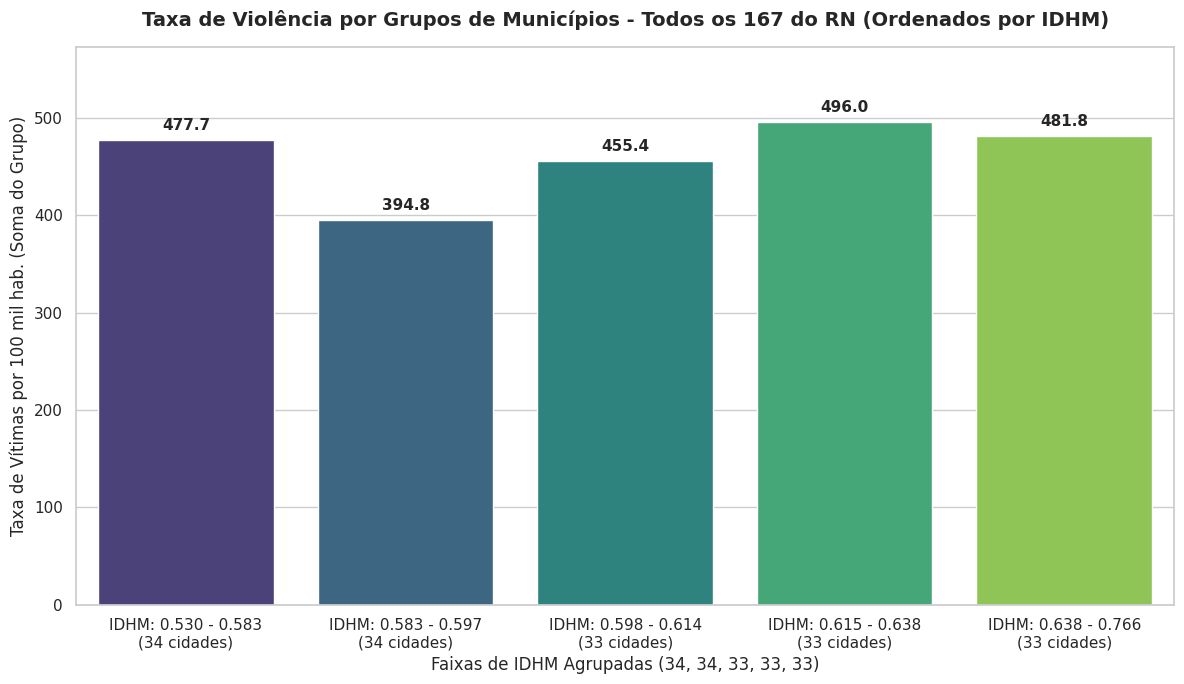

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import html
from pathlib import Path

# ==========================================
# 1. PREPARAR A BASE DO SINESP
# ==========================================
PASTA_SAIDA = Path("/content/resultados_cp1")
PASTA_EDA = PASTA_SAIDA / "analise_exploratoria_RN"
PASTA_EDA.mkdir(parents=True, exist_ok=True)

arquivo_rn = PASTA_SAIDA / "sinesp_limpo_estadual.csv"
df_rn = pd.read_csv(arquivo_rn, low_memory=False)
df_rn = df_rn[df_rn["uf"].astype(str).str.strip().str.upper() == "RN"].copy()
df_rn["total_vitima"] = pd.to_numeric(df_rn["total_vitima"], errors="coerce")
df_rn["evento"] = df_rn["evento"].astype(str).str.strip().str.title()

crimes_foco = [
    "Homicídio Doloso", "Feminicídio", "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte", "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]
df_foco = df_rn[df_rn["evento"].isin(crimes_foco)].copy()
df_foco = df_foco[~df_foco["municipio"].str.contains("Não Informado|Nao Informado", case=False, na=False)]

# Agrupar vítimas por município
vitimas_mun = df_foco.groupby("municipio")["total_vitima"].sum().reset_index()

# ==========================================
# 2. CARREGAR E LIMPAR A BASE DO IBGE
# ==========================================
arquivo_ibge = "bba6318174ce758f501d590704c5f324.csv"
df_socio = pd.read_csv(arquivo_ibge, skiprows=1)

df_socio.columns = [html.unescape(col) for col in df_socio.columns]
for col in df_socio.select_dtypes(include=['object']).columns:
    df_socio[col] = df_socio[col].apply(lambda x: html.unescape(str(x)) if pd.notnull(x) else x)

col_mun = [c for c in df_socio.columns if 'Município' in c][0]
col_pop = [c for c in df_socio.columns if 'População' in c and '2022' in c][0]
col_idhm = [c for c in df_socio.columns if 'IDHM' in c][0]

df_socio = df_socio[[col_mun, col_pop, col_idhm]].copy()
df_socio.columns = ['municipio_ibge', 'populacao', 'idhm']

df_socio['populacao'] = pd.to_numeric(df_socio['populacao'], errors='coerce')
df_socio['idhm'] = pd.to_numeric(df_socio['idhm'].astype(str).str.replace(',', '.').replace('-', np.nan), errors='coerce')

# ==========================================
# 3. NORMALIZAÇÃO E CRUZAMENTO (RIGHT MERGE)
# ==========================================
correcoes_nomes = {
    "assu": "acu",
    "augusto severo": "campo grande",
    "januario cicco": "boa saude",
    "olho d'agua do borges": "olho-d'agua do borges",
    "olho d agua do borges": "olho-d'agua do borges",
    "lagoa d'anta": "lagoa de anta",
    "lagoa d anta": "lagoa de anta"
}

def normalizar_nome(texto):
    if pd.isna(texto): return ""
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", errors="ignore").decode("utf-8")
    return correcoes_nomes.get(texto, texto)

vitimas_mun['chave'] = vitimas_mun['municipio'].apply(normalizar_nome)
df_socio['chave'] = df_socio['municipio_ibge'].apply(normalizar_nome)

df_final = pd.merge(vitimas_mun, df_socio, on='chave', how='right')
df_final['total_vitima'] = df_final['total_vitima'].fillna(0)
df_final = df_final.dropna(subset=['idhm', 'populacao'])

# ==========================================
# 4. AGRUPAMENTO (34, 34, 33, 33, 33)
# ==========================================
# Ordenamos pelo IDHM (do menor para o maior)
df_final = df_final.sort_values(by='idhm', ascending=True).reset_index(drop=True)

# Lógica condicional para forçar a divisão exata dos 167 municípios
condicoes = [
    df_final.index < 34,                                # Grupo 1: 34 cidades (índices 0 a 33)
    (df_final.index >= 34) & (df_final.index < 68),     # Grupo 2: 34 cidades (índices 34 a 67)
    (df_final.index >= 68) & (df_final.index < 101),    # Grupo 3: 33 cidades (índices 68 a 100)
    (df_final.index >= 101) & (df_final.index < 134),   # Grupo 4: 33 cidades (índices 101 a 133)
    df_final.index >= 134                               # Grupo 5: 33 cidades (índices 134 a 166)
]
grupos = [1, 2, 3, 4, 5]
df_final['grupo_idhm'] = np.select(condicoes, grupos)

# Agrupar e calcular as somas e limites de IDHM
resumo_grupos = df_final.groupby('grupo_idhm').agg(
    total_vitima_grupo=('total_vitima', 'sum'),
    populacao_grupo=('populacao', 'sum'),
    idhm_min=('idhm', 'min'),
    idhm_max=('idhm', 'max'),
    qtd_cidades=('municipio_ibge', 'count')
).reset_index()

# Calcular a taxa de letalidade violenta por 100k para cada bloco
resumo_grupos['taxa_100k'] = (resumo_grupos['total_vitima_grupo'] / resumo_grupos['populacao_grupo']) * 100000

# Criar um rótulo legível para o eixo X
resumo_grupos['rotulo'] = resumo_grupos.apply(
    lambda row: f"IDHM: {row['idhm_min']:.3f} - {row['idhm_max']:.3f}\n({int(row['qtd_cidades'])} cidades)", axis=1
)

print(f"Total de Cidades Processadas: {resumo_grupos['qtd_cidades'].sum()}")

# ==========================================
# 5. GRÁFICO
# ==========================================
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=resumo_grupos,
    x='rotulo',
    y='taxa_100k',
    palette='viridis',
    legend=False
)

plt.title("Taxa de Violência por Grupos de Municípios - Todos os 167 do RN (Ordenados por IDHM)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Faixas de IDHM Agrupadas (34, 34, 33, 33, 33)", fontsize=12)
plt.ylabel("Taxa de Vítimas por 100 mil hab. (Soma do Grupo)", fontsize=12)

# Adicionar os números acima das barras
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', label_type='edge', padding=5, fontweight='bold', fontsize=11)

# Aumentar levemente o limite Y para o texto não sobrepor a borda do gráfico
y_min, y_max = plt.ylim()
plt.ylim(y_min, y_max * 1.1)

plt.tight_layout()
plt.savefig(PASTA_EDA / "22_violencia_agrupada_exata_idhm.png", bbox_inches='tight')
plt.show()

/tmp/ipykernel_4766/2638406609.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=df_regiao_final, x='rotulo', y='taxa_100k', palette='magma', legend=False)


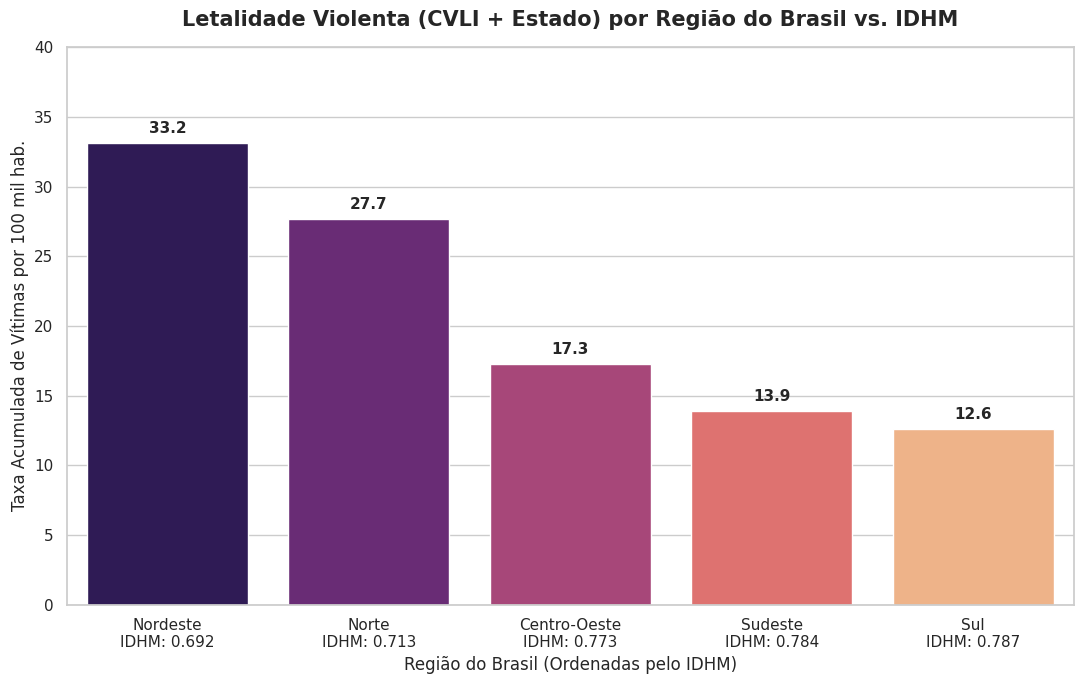

In [ ]:
# 1. MAPEAMENTO DE REGIÕES E CVLI
dict_regioes = {
    'Norte': ['AM', 'RR', 'AP', 'PA', 'TO', 'RO', 'AC'],
    'Nordeste': ['MA', 'PI', 'CE', 'RN', 'PB', 'PE', 'AL', 'SE', 'BA'],
    'Centro-Oeste': ['MT', 'MS', 'GO', 'DF'],
    'Sudeste': ['SP', 'RJ', 'MG', 'ES'],
    'Sul': ['PR', 'RS', 'SC']
}

# Inverter dicionário para mapear UF -> Região facilmente
uf_para_regiao = {uf: regiao for regiao, ufs in dict_regioes.items() for uf in ufs}
df_br_est['regiao'] = df_br_est['uf'].map(uf_para_regiao)

crimes_cvli = [
    "Homicídio Doloso", "Feminicídio", "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte", "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Filtrar apenas crimes letais intencionais
df_cvli_reg = df_br_est[df_br_est["evento"].isin(crimes_cvli)].copy()

# 2. AGRUPAR VÍTIMAS E POPULAÇÃO POR REGIÃO
vitimas_regiao = df_cvli_reg.groupby('regiao')['total_vitima'].sum().reset_index()

# Converter o dict_pop_uf para DataFrame para agrupar a população do Censo por Região
pop_regiao = pd.DataFrame(list(dict_pop_uf.items()), columns=['uf', 'populacao'])
pop_regiao['regiao'] = pop_regiao['uf'].map(uf_para_regiao)
pop_regiao_agg = pop_regiao.groupby('regiao')['populacao'].sum().reset_index()

# Dicionário com o IDHM consolidado por Região (PNUD/IPEA)
dict_idhm_regiao = {
    'Sul': 0.787,
    'Sudeste': 0.784,
    'Centro-Oeste': 0.773,
    'Norte': 0.713,
    'Nordeste': 0.692
}

# Juntar vítimas e população
df_regiao_final = pd.merge(vitimas_regiao, pop_regiao_agg, on='regiao')

# Calcular a taxa de CVLI por 100k habitantes da região inteira
df_regiao_final['taxa_100k'] = (df_regiao_final['total_vitima'] / df_regiao_final['populacao']) * 100000

# Adicionar o IDHM
df_regiao_final['idhm'] = df_regiao_final['regiao'].map(dict_idhm_regiao)

# Ordenar do menor para o maior IDHM
df_regiao_final = df_regiao_final.sort_values('idhm', ascending=True)

# Criar rótulo explicativo para o Eixo X
df_regiao_final['rotulo'] = df_regiao_final.apply(lambda row: f"{row['regiao']}\nIDHM: {row['idhm']:.3f}", axis=1)

# 3. GRÁFICO
plt.figure(figsize=(11, 7))
sns.set_theme(style="whitegrid")

# Paleta de cores para realçar a gravidade
ax2 = sns.barplot(data=df_regiao_final, x='rotulo', y='taxa_100k', palette='magma', legend=False)

plt.title("Letalidade Violenta (CVLI + Estado) por Região do Brasil vs. IDHM", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Região do Brasil (Ordenadas pelo IDHM)", fontsize=12)
plt.ylabel("Taxa Acumulada de Vítimas por 100 mil hab.", fontsize=12)

# Adicionar valores sobre as barras
for c in ax2.containers:
    ax2.bar_label(c, fmt='%.1f', padding=5, fontweight='bold', fontsize=11)

# Ajustar eixo Y para dar espaço ao texto
y_min, y_max = plt.ylim()
plt.ylim(y_min, y_max * 1.15)

plt.tight_layout()
plt.savefig(PASTA_EDA / "25_taxa_cvli_regiao_idhm.png", bbox_inches='tight')
plt.show()

In [ ]:
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================
#CRIMES SEM A INTERVENÇÃO DO ESTADO(POLÍCIA)
#==========================================================================================================================================================================================================
#==========================================================================================================================================================================================================

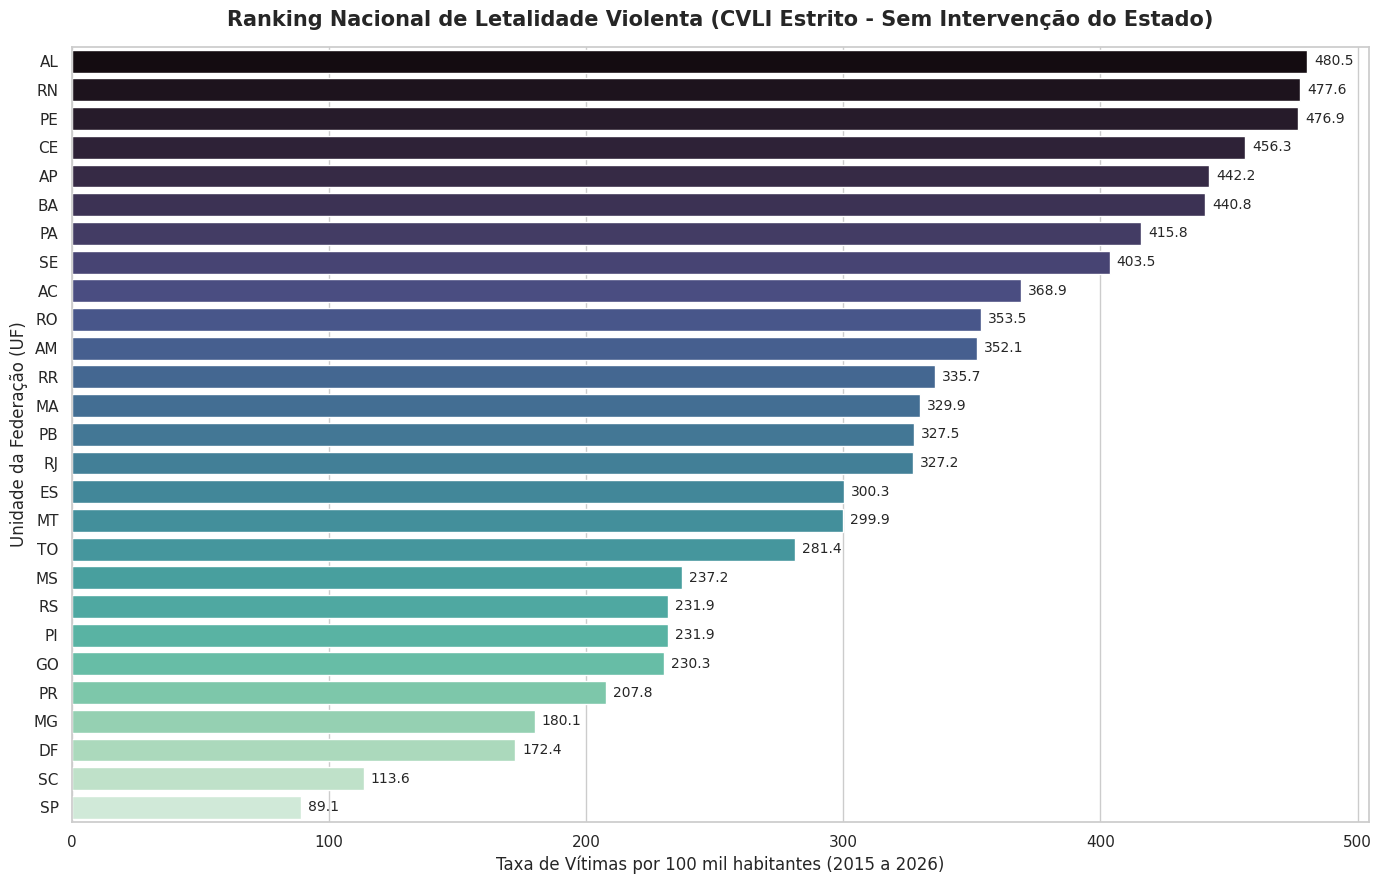

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

# Garantir a pasta de saída
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. CARREGAR A BASE DIRETAMENTE DA MEMÓRIA RAM (Variável df_estado)
df_br_cvli = df_estado.copy()

df_br_cvli["total_vitima"] = pd.to_numeric(
    df_br_cvli["total_vitima"], errors="coerce"
).fillna(0)
df_br_cvli["evento"] = (
    df_br_cvli["evento"].astype(str).str.strip().str.title()
)
df_br_cvli["uf"] = df_br_cvli["uf"].astype(str).str.strip().str.upper()

# Dicionário de População por UF (Censo IBGE 2022)
dict_pop_uf = {
    "SP": 44411238,
    "MG": 20538718,
    "RJ": 16054524,
    "BA": 14141626,
    "PR": 11444380,
    "RS": 10882965,
    "PE": 9058931,
    "CE": 8794957,
    "PA": 8121025,
    "SC": 7610361,
    "GO": 7056495,
    "MA": 6775805,
    "PB": 3974687,
    "AM": 3941613,
    "ES": 3833712,
    "MT": 3658649,
    "RN": 3302729,
    "PI": 3271199,
    "AL": 3127683,
    "DF": 2817381,
    "MS": 2757013,
    "SE": 2209558,
    "RO": 1581196,
    "TO": 1511460,
    "AC": 830018,
    "AP": 733759,
    "RR": 636227,
}

df_br_cvli["populacao"] = df_br_cvli["uf"].map(dict_pop_uf)

# 2. FILTRAR OS CRIMES (CVLI ESTRITO - EXCLUINDO LETALIDADE POLICIAL)
crimes_cvli_estrito = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte De Agente Do Estado",
]
# Nota: O evento "Morte Por Intervenção De Agente Do Estado" foi intencionalmente removido da lista

df_filtrado = df_br_cvli[df_br_cvli["evento"].isin(crimes_cvli_estrito)].copy()

# Agrupar total de vítimas por UF
agrupado_uf = (
    df_filtrado.groupby(["uf", "populacao"])["total_vitima"].sum().reset_index()
)

# Calcular a taxa de CVLI Estrito por 100 mil habitantes
agrupado_uf["taxa_100k"] = (
    agrupado_uf["total_vitima"] / agrupado_uf["populacao"]
) * 100000
agrupado_uf = agrupado_uf.sort_values("taxa_100k", ascending=False)

# 3. GRÁFICO
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

# Usar uma paleta de cores diferente (mako) para não confundir com o gráfico da polícia (que era vermelho)
ax = sns.barplot(
    data=agrupado_uf, x="taxa_100k", y="uf", hue="uf", palette="mako", legend=False
)

plt.title(
    "Ranking Nacional de Letalidade Violenta (CVLI Estrito - Sem Intervenção"
    " do Estado)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Taxa de Vítimas por 100 mil habitantes (2015 a 2026)", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os rótulos nas barras
for c in ax.containers:
  ax.bar_label(c, fmt="%.1f", padding=5, fontsize=10)

plt.tight_layout()
plt.savefig(PASTA_EDA / "26_ranking_cvli_sem_estado_uf.png", bbox_inches="tight")
plt.show()

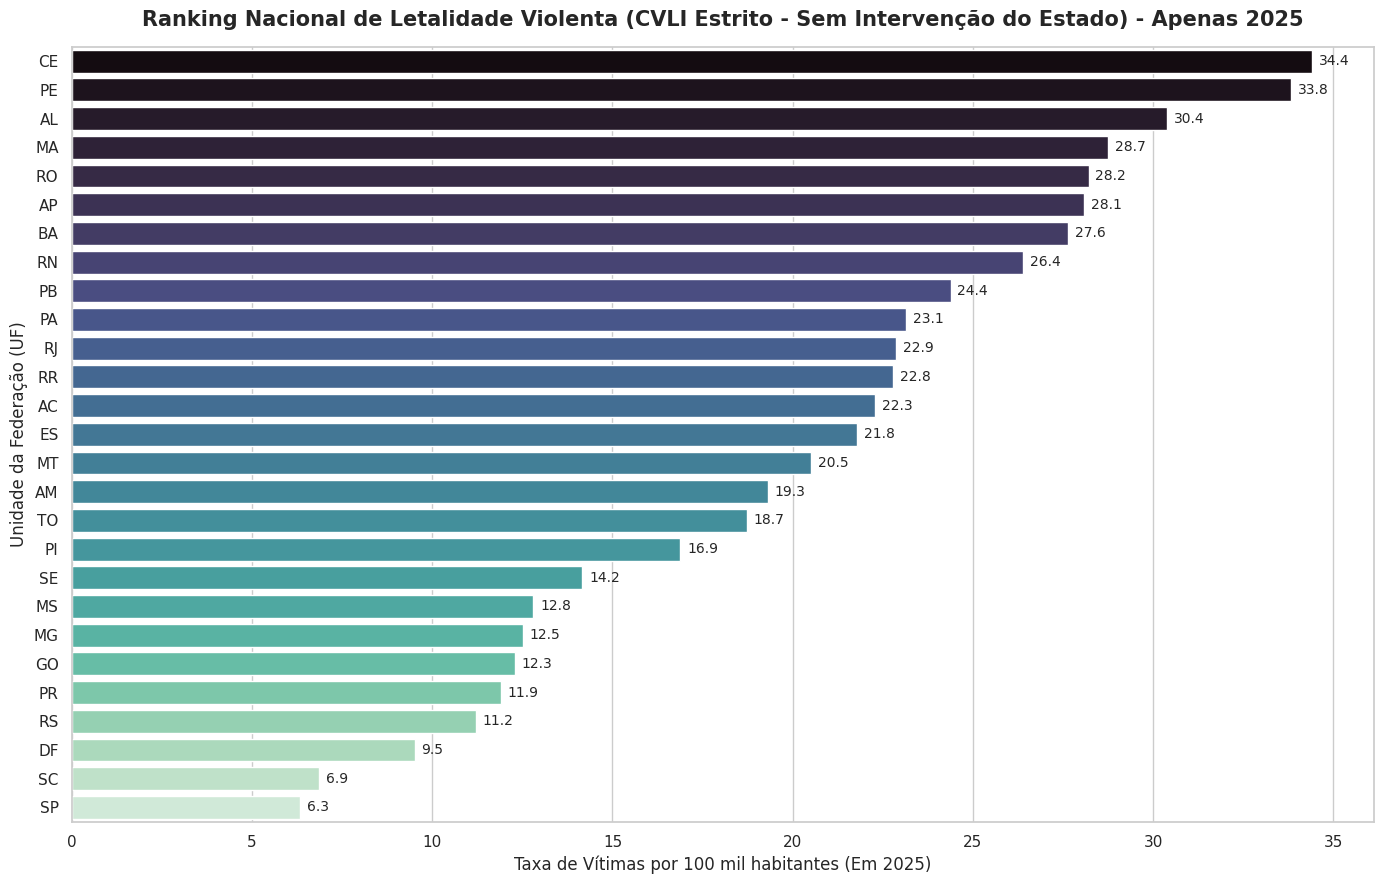

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Garantir a pasta de saída
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)

# 1. CARREGAR A BASE DIRETAMENTE DA MEMÓRIA RAM (Variável df_estado)
df_br_cvli = df_estado.copy()

# ----------------------------------------------------
# NOVO PASSO: Extrair o ano e filtrar apenas para 2025
# ----------------------------------------------------
df_br_cvli["ano"] = pd.to_datetime(
    df_br_cvli["data_referencia"], errors="coerce"
).dt.year
df_br_cvli = df_br_cvli[df_br_cvli["ano"] == 2025].copy()

df_br_cvli["total_vitima"] = pd.to_numeric(
    df_br_cvli["total_vitima"], errors="coerce"
).fillna(0)
df_br_cvli["evento"] = (
    df_br_cvli["evento"].astype(str).str.strip().str.title()
)
df_br_cvli["uf"] = df_br_cvli["uf"].astype(str).str.strip().str.upper()

# Dicionário de População por UF (Censo IBGE 2022)
dict_pop_uf = {
    "SP": 44411238,
    "MG": 20538718,
    "RJ": 16054524,
    "BA": 14141626,
    "PR": 11444380,
    "RS": 10882965,
    "PE": 9058931,
    "CE": 8794957,
    "PA": 8121025,
    "SC": 7610361,
    "GO": 7056495,
    "MA": 6775805,
    "PB": 3974687,
    "AM": 3941613,
    "ES": 3833712,
    "MT": 3658649,
    "RN": 3302729,
    "PI": 3271199,
    "AL": 3127683,
    "DF": 2817381,
    "MS": 2757013,
    "SE": 2209558,
    "RO": 1581196,
    "TO": 1511460,
    "AC": 830018,
    "AP": 733759,
    "RR": 636227,
}

df_br_cvli["populacao"] = df_br_cvli["uf"].map(dict_pop_uf)

# 2. FILTRAR OS CRIMES (CVLI ESTRITO - EXCLUINDO LETALIDADE POLICIAL)
crimes_cvli_estrito = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte De Agente Do Estado",
]
# Nota: O evento "Morte Por Intervenção De Agente Do Estado" foi intencionalmente removido da lista

df_filtrado = df_br_cvli[df_br_cvli["evento"].isin(crimes_cvli_estrito)].copy()

# Agrupar total de vítimas por UF
agrupado_uf = (
    df_filtrado.groupby(["uf", "populacao"])["total_vitima"].sum().reset_index()
)

# Calcular a taxa de CVLI Estrito por 100 mil habitantes
agrupado_uf["taxa_100k"] = (
    agrupado_uf["total_vitima"] / agrupado_uf["populacao"]
) * 100000
agrupado_uf = agrupado_uf.sort_values("taxa_100k", ascending=False)

# 3. GRÁFICO
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid")

# Usar uma paleta de cores diferente (mako)
ax = sns.barplot(
    data=agrupado_uf, x="taxa_100k", y="uf", hue="uf", palette="mako", legend=False
)

# Título e Eixos atualizados para focar exclusivamente em 2025
plt.title(
    "Ranking Nacional de Letalidade Violenta (CVLI Estrito - Sem Intervenção"
    " do Estado) - Apenas 2025",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Taxa de Vítimas por 100 mil habitantes (Em 2025)", fontsize=12)
plt.ylabel("Unidade da Federação (UF)", fontsize=12)

# Adicionar os rótulos nas barras
for c in ax.containers:
  ax.bar_label(c, fmt="%.1f", padding=5, fontsize=10)

plt.tight_layout()
plt.savefig(
    PASTA_EDA / "27_ranking_cvli_sem_estado_uf_2025.png", bbox_inches="tight"
)
plt.show()

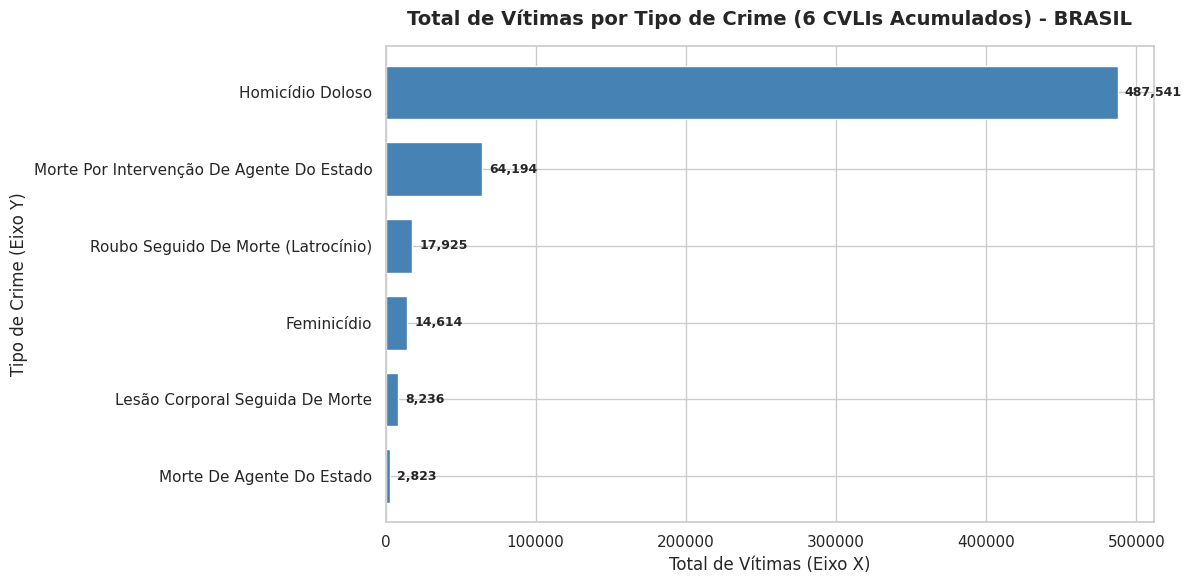

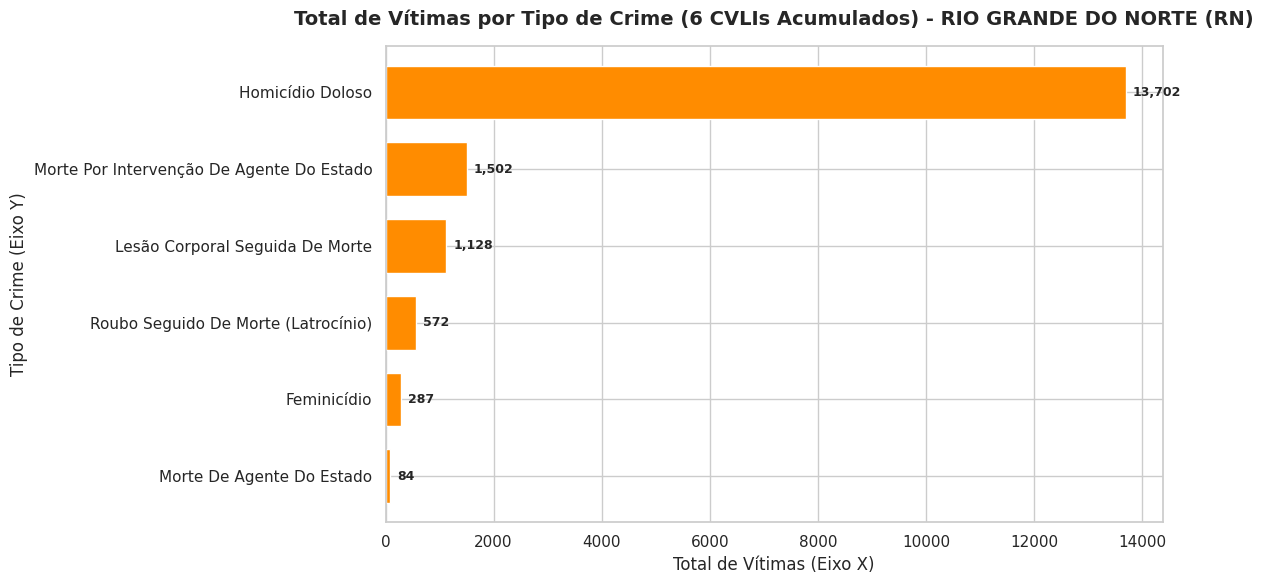

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==========================================
# 0. CONFIGURAÇÃO E RECUPERAÇÃO DA MEMÓRIA
# ==========================================
PASTA_EDA = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_EDA.mkdir(parents=True, exist_ok=True)

if 'df_estado' in locals():
    df_base = df_estado.copy()
elif 'df_completo' in locals():
    df_base = df_completo.copy()
else:
    raise NameError("Nenhuma base de dados encontrada na memória. Execute a célula de carregamento primeiro.")

# ==========================================
# 1. TRATAMENTO DOS DADOS
# ==========================================
df_base["total_vitima"] = pd.to_numeric(df_base["total_vitima"], errors="coerce").fillna(0)
df_base["evento"] = df_base["evento"].astype(str).str.strip().str.title()
df_base["uf"] = df_base["uf"].astype(str).str.strip().str.upper()

# Os 6 crimes de CVLI e Letalidade definidos
crimes_6_definidos = [
    "Homicídio Doloso",
    "Feminicídio",
    "Roubo Seguido De Morte (Latrocínio)",
    "Lesão Corporal Seguida De Morte",
    "Morte Por Intervenção De Agente Do Estado",
    "Morte De Agente Do Estado"
]

# Filtra apenas os 6 crimes definidos
df_6 = df_base[df_base["evento"].isin(crimes_6_definidos)]

# ==========================================
# 2. AGREGAÇÃO: BRASIL E RN (Somando o período total por tipo de crime)
# ==========================================
# Brasil - Soma acumulada por tipo de crime
br_6 = df_6.groupby("evento")["total_vitima"].sum().sort_values(ascending=True)

# Rio Grande do Norte (RN) - Soma acumulada por tipo de crime
df_rn = df_6[df_6["uf"] == "RN"]
rn_6 = df_rn.groupby("evento")["total_vitima"].sum().sort_values(ascending=True)

# ==========================================
# 3. GRÁFICO 1: BRASIL (Barras Horizontais)
# ==========================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax1 = br_6.plot(kind="barh", color="steelblue", width=0.7)

plt.title("Total de Vítimas por Tipo de Crime (6 CVLIs Acumulados) - BRASIL", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Total de Vítimas (Eixo X)", fontsize=12)
plt.ylabel("Tipo de Crime (Eixo Y)", fontsize=12)

# Adiciona os valores nas barras horizontais
for p in ax1.patches:
    width = p.get_width()
    if width > 0:
        ax1.annotate(f'{int(width):,}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    fontsize=9, fontweight='bold',
                    xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.savefig(PASTA_EDA / "38_horizontal_6_crimes_brasil.png", bbox_inches='tight')
plt.show()

# ==========================================
# 4. GRÁFICO 2: RIO GRANDE DO NORTE - RN (Barras Horizontais)
# ==========================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax2 = rn_6.plot(kind="barh", color="darkorange", width=0.7)

plt.title("Total de Vítimas por Tipo de Crime (6 CVLIs Acumulados) - RIO GRANDE DO NORTE (RN)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Total de Vítimas (Eixo X)", fontsize=12)
plt.ylabel("Tipo de Crime (Eixo Y)", fontsize=12)

# Adiciona os valores nas barras horizontais
for p in ax2.patches:
    width = p.get_width()
    if width > 0:
        ax2.annotate(f'{int(width):,}',
                    (width, p.get_y() + p.get_height() / 2.,),
                    ha='left', va='center',
                    fontsize=9, fontweight='bold',
                    xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.savefig(PASTA_EDA / "39_horizontal_6_crimes_rn.png", bbox_inches='tight')
plt.show()

In [ ]:
import shutil
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PASTA_ORIGEM = Path("/content/resultados_cp1/analise_exploratoria_RN")
PASTA_DRIVE = Path("/content/drive/MyDrive/Relatorio_Seguranca_RN/figuras")
PASTA_DRIVE.mkdir(parents=True, exist_ok=True)

# Copia todas as imagens PNG geradas para o Drive
for img in PASTA_ORIGEM.glob("*.png"):
  shutil.copy2(img, PASTA_DRIVE / img.name)

print(
    f"Imagens salvas em: {PASTA_DRIVE} ({len(list(PASTA_DRIVE.glob('*.png')))} arquivos)"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Imagens salvas em: /content/drive/MyDrive/Relatorio_Seguranca_RN/figuras (21 arquivos)
